# 106 · Which lasers and which frequencies does the model read?

Run: **s8-best-spkgain-500ep** (set `RUN=` to change it). It is compared with s8-best-mag-500ep, and with s8-mag-drop once that run finishes. Data: `src8/importance.py` (occlusion) and `src8/gradcam.py` (Grad-CAM) → `runs/<run>/importance*.pt`, `gradcam.pt`.

**Occlusion: take part of the input away, re-run the model, and measure how much worse the mask gets.** Damage > 0 (red) means the model needs that part. Damage < 0 (blue) means the prediction improves without it.

**Three ways of taking a laser or a band away (the baseline):**

| baseline | what replaces it | what it measures | caveat |
|---|---|---|---|
| `mean` | the box's mean signal over the eval set | the sample-specific information there | an unnaturally smooth spectrum the model never sees |
| `resample` | the same laser / band from another recording of the same box | the same, with a realistic spectrum (permutation importance) | one random partner per sample: noisier per sample, fine averaged |
| `remove` | nothing: masked out of attention and the band gate, its slots zeroed | true removal | only in distribution for a model trained with laser / band dropout (s8-mag-drop) |

Zeros are not used: the model never sees them in training, so they would measure its surprise, not its reliance.

**Metrics.** Each one shows a different way a band can matter:
- **iou@0.08**: the headline metric. Thresholded, so it is step-like for small occlusions.
- **soft IoU**: continuous and the least noisy. It is used to *rank* bands and lasers for the top-k curves.
- **miss@0.08**: the other headline metric; the rate of masks with no pixel on the object.
- **centroid error**: localization only, in % of the box.
- **orientation error**: the principal-axis error in degrees, for elongated objects only. It asks which bands carry *rotation*.

**Top-k curves, next to every heatmap.** Rank the bands (or lasers) by their soft-IoU damage for that box. Then:
- **keep top k** (solid): take away everything except the k most important, and score the model.
- **remove top k** (dashed): take away the k most important.

A thin gray line repeats both for a random order, which a good ranking must beat. The dotted line is the full-input score.

**What to keep in mind:**
- **Redundancy.** Marginal (one-at-a-time) occlusion underestimates parts whose information is duplicated elsewhere, such as neighbouring lasers. The top-k curves catch this: a steep *keep top k* curve with a flat *remove one* heatmap means redundancy.
- **Interactions.** Two bands can matter only together. The joint laser × band map covers one kind of pair.
- **Noise.** Single-cell effects are tiny. Read sums and rankings, not individual cells.
- **Attention weights are not importance.** The band gates are within 1.5% of uniform, and a later linear layer can rescale anything.

**Colours, everywhere in this notebook.** In a heatmap, colour is always the value: red = needed, blue = removing it helps, gray = 0. Unsigned maps use sequential blue. Boxes are told apart by a thick bar on the panel's left edge, in the box's colour (cardboard blue, gastro orange, plastic green), which matches that box's top-k curve.

Samples: CORE (vase / cube / soap / candle × 3 boxes) + HARD (cardboard rotated soap). Marginal maps and curves use every eval sample. The joint map and Grad-CAM use 200 per box.

In [2]:
import os, json, torch, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import spearmanr
from pathlib import Path
ROOT = Path(os.environ.get('NB106_ROOT', '..' if Path('../runs').exists() else '.')).resolve()

RUN, COMPARE = os.environ.get('RUN', 's8-best-spkgain-500ep'), os.environ.get('COMPARE', 's8-best-mag-500ep')

FILES = {'mean': 'importance.pt', 'resample': 'importance_resample.pt', 'remove': 'importance_remove.pt'}
def load(run): return {k: torch.load(ROOT / 'runs' / run / f) for k, f in FILES.items() if (ROOT / 'runs' / run / f).exists()}
I = load(RUN)
if 'mean' not in I:
    have = sorted(r.name for r in (ROOT / 'runs').iterdir() if (r / 'importance.pt').exists())
    raise FileNotFoundError(f'{RUN}: no runs/{RUN}/importance.pt yet (src8/importance.py has not run on it; queued runs are in '
                            f'scripts/modal_src8_queue5.sh). Runs with importance: {have}')
d = I['mean']
args = json.load(open(ROOT / 'runs' / RUN / 'args.json')) if (ROOT / 'runs' / RUN / 'args.json').exists() else {}
if 'remove' in I and not (args.get('laser_drop', 0) or args.get('band_drop', 0)):
    print('note: remove on a model trained without dropout is out of distribution');
BASELINES = list(I)
CAM = torch.load(ROOT / 'runs' / RUN / 'gradcam.pt') if (ROOT / 'runs' / RUN / 'gradcam.pt').exists() else None
BOX_NAMES = {'gastronorm': 'gastro', 'green-plastic': 'plastic', 'cardboard': 'cardboard'}
boxes = [BOX_NAMES.get(b, b) for b in d['boxes']]; nb = len(boxes)
hz, bhz, (rows, cols) = d['hz'].numpy(), d['bin_hz'].numpy(), d['grid']
P, BAND = len(hz), 64
EDGES = np.array([bhz[min(j * BAND, len(bhz) - 1)] for j in range(P)] + [bhz[-1]])   # band borders in Hz (the last band is short: 18 bins)
def band_range(j): return f'{EDGES[j]:.0f}–{EDGES[j + 1]:.0f} Hz'
# metric -> (display scale, cell format, label)
UNIT = {'iou@0.08': (1, '{:+.3f}', 'iou@0.08'), 'soft_iou': (1, '{:+.3f}', 'soft IoU'), 'miss@0.08': (1, '{:+.3f}', 'miss rate @0.08'),
        'com_err': (100, '{:+.2f}', 'centroid error (% of box)'), 'orient_err': (1, '{:+.1f}', 'orientation error (deg)')}
# validated palette (dataviz skill): categorical slots 1-3 per box (line charts only); diverging blue <-> gray <-> red for signed damage
# (red = the model needs it); sequential blue for unsigned maps (Grad-CAM, |IG|). Heatmaps never encode the box by colour
BOXC = ['#2a78d6', '#eb6834', '#1baf7a']
DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#e34948'])
SEQ = LinearSegmentedColormap.from_list('seq', ['#f7fafe', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'font.size': 10})

def fmt(v, f='{:+.3f}'): return 'nan' if np.isnan(v) else f.format(v).replace('0.', '.', 1) if f == '{:+.3f}' else f.format(v)
def heat(ax, m, lim, f='{:+.3f}', annotate=True, fs=8, cmap=DIV, signed=True, **kw):
    """m (r,c) on the shared scale: diverging around 0 (signed) or sequential from 0 (unsigned); cells labelled, white ink on dark cells"""
    lim = float(lim) if np.isfinite(lim) and lim > 0 else 1e-6                          # an all-zero metric (e.g. no misses at all)
    norm = TwoSlopeNorm(0, -lim, lim) if signed else plt.Normalize(0, lim)
    im = ax.imshow(m, cmap=cmap if signed else SEQ, norm=norm, interpolation='nearest', **kw)
    for s in ax.spines.values(): s.set_visible(False)
    if annotate:
        for (i, j), v in np.ndenumerate(m):
            dark = abs(v) > .6 * lim if signed else v > .6 * lim
            ax.text(j, i, fmt(v, f), ha='center', va='center', fontsize=fs, color='white' if dark else '#222')
    return im
def tag(ax, b):
    """box identity: a thick bar in the box's colour on the panel's left edge (the heatmap colour itself always means the value)"""
    sp = ax.spines['left']; sp.set_visible(True); sp.set_color(BOXC[b]); sp.set_linewidth(7)
def band_axis(ax, labels=True):
    """x ticks on the band borders (where the white lines are), labelled in Hz"""
    ax.set_xticks(np.arange(P + 1) - .5, [f'{e:.0f}' for e in EDGES] if labels else [], rotation=0 if labels else 0, fontsize=8)
    for x in np.arange(.5, P - 1, 1): ax.axvline(x, color='white', lw=1.2)
def topk(ax, D, kind, k, b, s, legend=False):
    """absolute metric vs k: keep only the top k (solid) / remove the top k (dashed); ranked in the box colour, random in gray"""
    C = D['curves']
    ks = np.array(D[f'{kind}_k'])
    for order, col, lw in (('random', '#b5b5b5', 1.2), ('ranked', BOXC[b], 2)):
        ax.plot(ks, C[f'{kind}_{order}_ins'][k, b] * s, '-', color=col, lw=lw, marker='o', ms=3, label=f'{order}: keep top k')
        ax.plot(ks, C[f'{kind}_{order}_del'][k, b] * s, '--', color=col, lw=lw, label=f'{order}: remove top k')
    ax.axhline(D['base'][k, b] * s, color='#555', lw=.8, ls=':', label='full input')
    ax.set_xlabel(f'k ({kind}s)'); ax.grid(axis='y', color='#eee')
    if legend: ax.legend(frameon=False, fontsize=7, loc='best')

print('run:', RUN, '| baselines:', BASELINES, '| checkpoint', d['ckpt'], '| grad-cam:', CAM is not None)
for b, bn in enumerate(boxes):
    print(f'  {bn:10s} n={int(d["n"][b]):4d}  base ' + '  '.join(f'{m} {d["base"][k, b] * UNIT[m][0]:.3f}' for k, m in enumerate(d['metrics'])))

run: s8-best-spkgain-500ep | baselines: ['mean'] | checkpoint ep500-ba5500-rank0.pt | grad-cam: False
  cardboard  n=1000  base iou@0.08 0.696  soft_iou 0.703
  gastro     n= 612  base iou@0.08 0.716  soft_iou 0.727
  plastic    n= 842  base iou@0.08 0.744  soft_iou 0.759


## 1 · Frequency: which ~49 Hz bands matter
One figure per metric and baseline. Each box is a row of 19 bands, labelled with its damage, and its top-k curve sits to the right. The colour scale is shared by the three boxes within a figure. The x ticks mark the band borders.

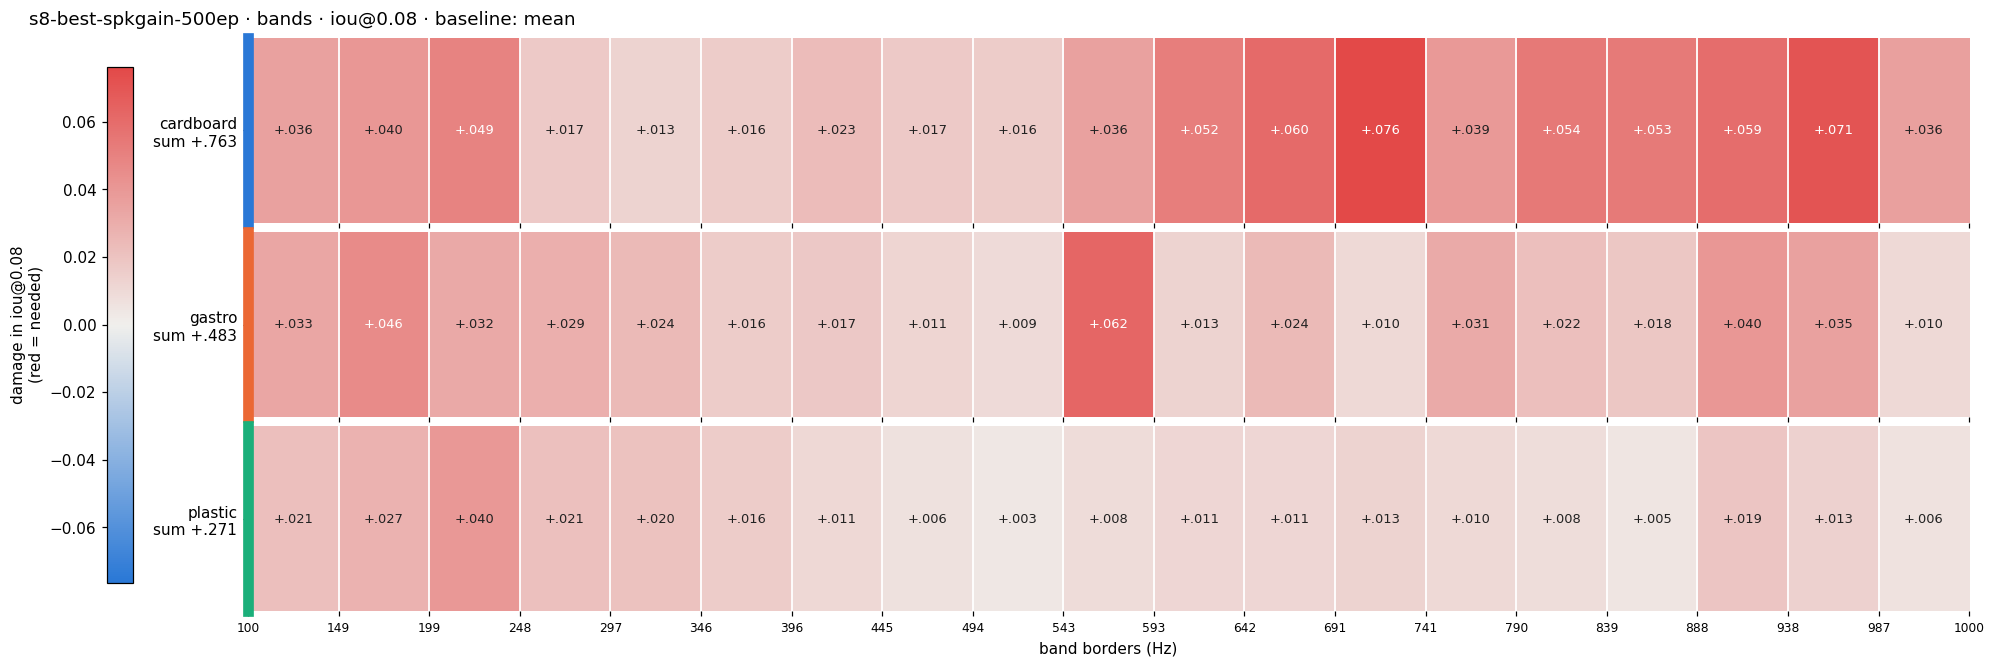

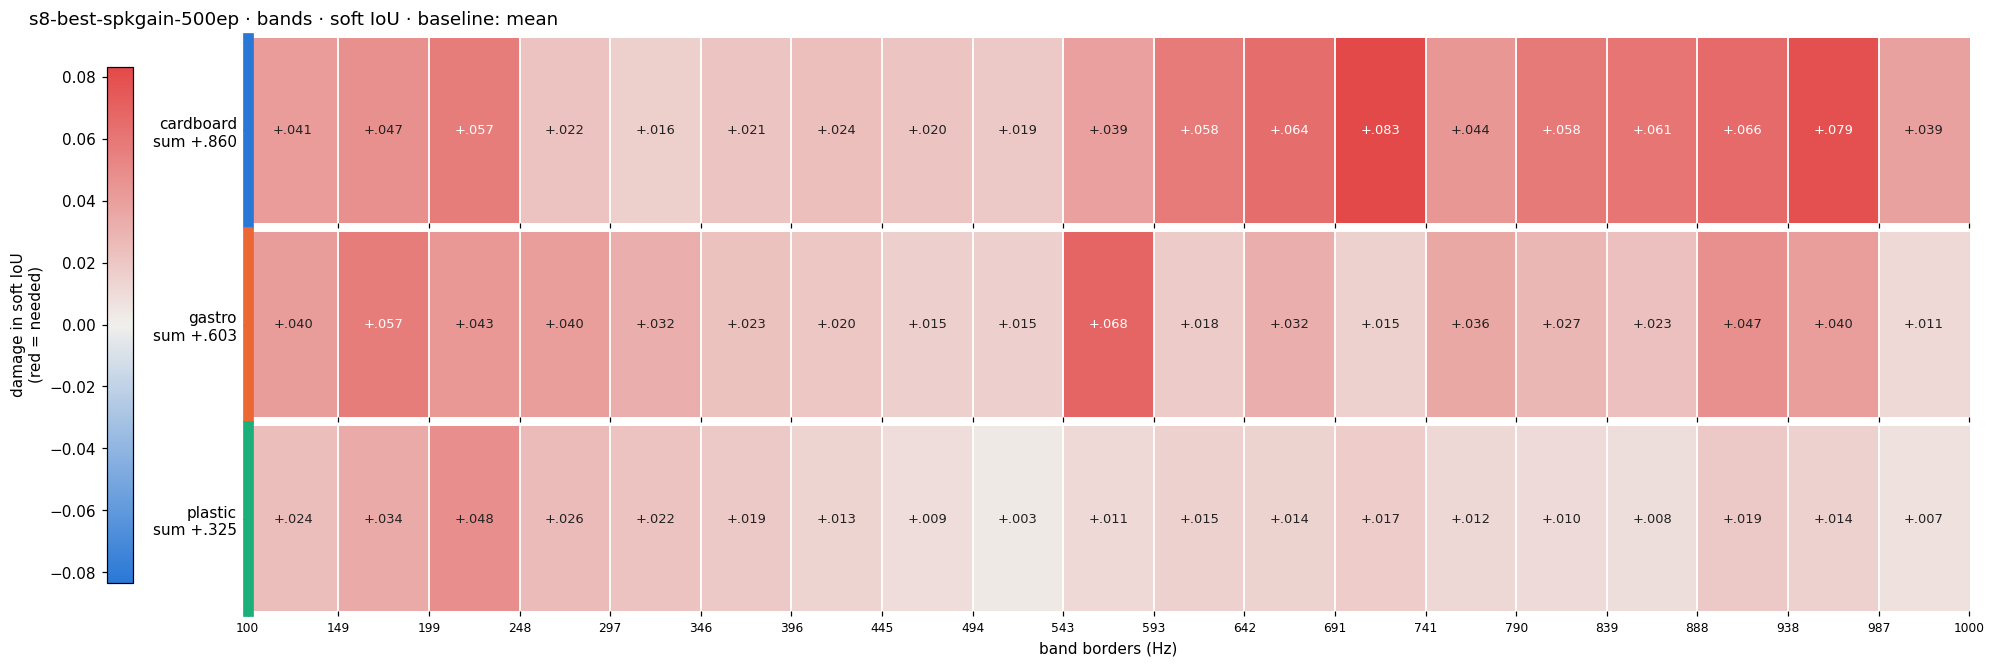

In [ ]:
def band_figure(base, metric):
    D = I[base]; k = D['metrics'].index(metric); s, f, lab = UNIT[metric]
    B = D['band'][k].numpy() * s; lim = np.nanmax(np.abs(B))
    curves = 'curves' in D
    fig = plt.figure(figsize=(21 if curves else 18, 1.55 * nb + 1.3), layout='constrained')
    gs = fig.add_gridspec(nb, 2 if curves else 1, width_ratios=[5.2, 1] if curves else [1])
    hax = []
    for b, bn in enumerate(boxes):
        ax = fig.add_subplot(gs[b, 0]); hax.append(ax)
        im = heat(ax, B[b:b + 1], lim, f, fs=8.5, aspect='auto'); band_axis(ax, labels=b == nb - 1); tag(ax, b)
        ax.set_yticks([0], [f'{bn}\nsum {fmt(np.nansum(B[b]), f)}'])
        if curves:
            cx = fig.add_subplot(gs[b, 1]); topk(cx, D, 'band', k, b, s, legend=b == 0); cx.set_ylabel(lab, fontsize=8)
            if b < nb - 1: cx.set_xlabel('')
    hax[-1].set_xlabel('band borders (Hz)')
    fig.colorbar(im, ax=hax, location='left', shrink=.9, pad=.01, label=f'damage in {lab}\n(red = needed)')
    fig.suptitle(f'{RUN} · bands · {lab} · baseline: {base}', x=.01, ha='left', fontsize=12); plt.show()

for metric in d['metrics']:
    for base in BASELINES:
        if metric in I[base]['metrics']: band_figure(base, metric)

## 2 · Lasers: which spots on the wall matter
Top row: the 10 × 10 laser grid on the wall for each box (laser l → row l // 10, column l % 10), each cell labelled with its damage. Bottom row: that box's top-k curve, directly below its grid. The colours mean the same as in the frequency plots, but the scale is the figure's own: one laser matters about 10× less than one band, so a shared scale would leave these maps all gray.

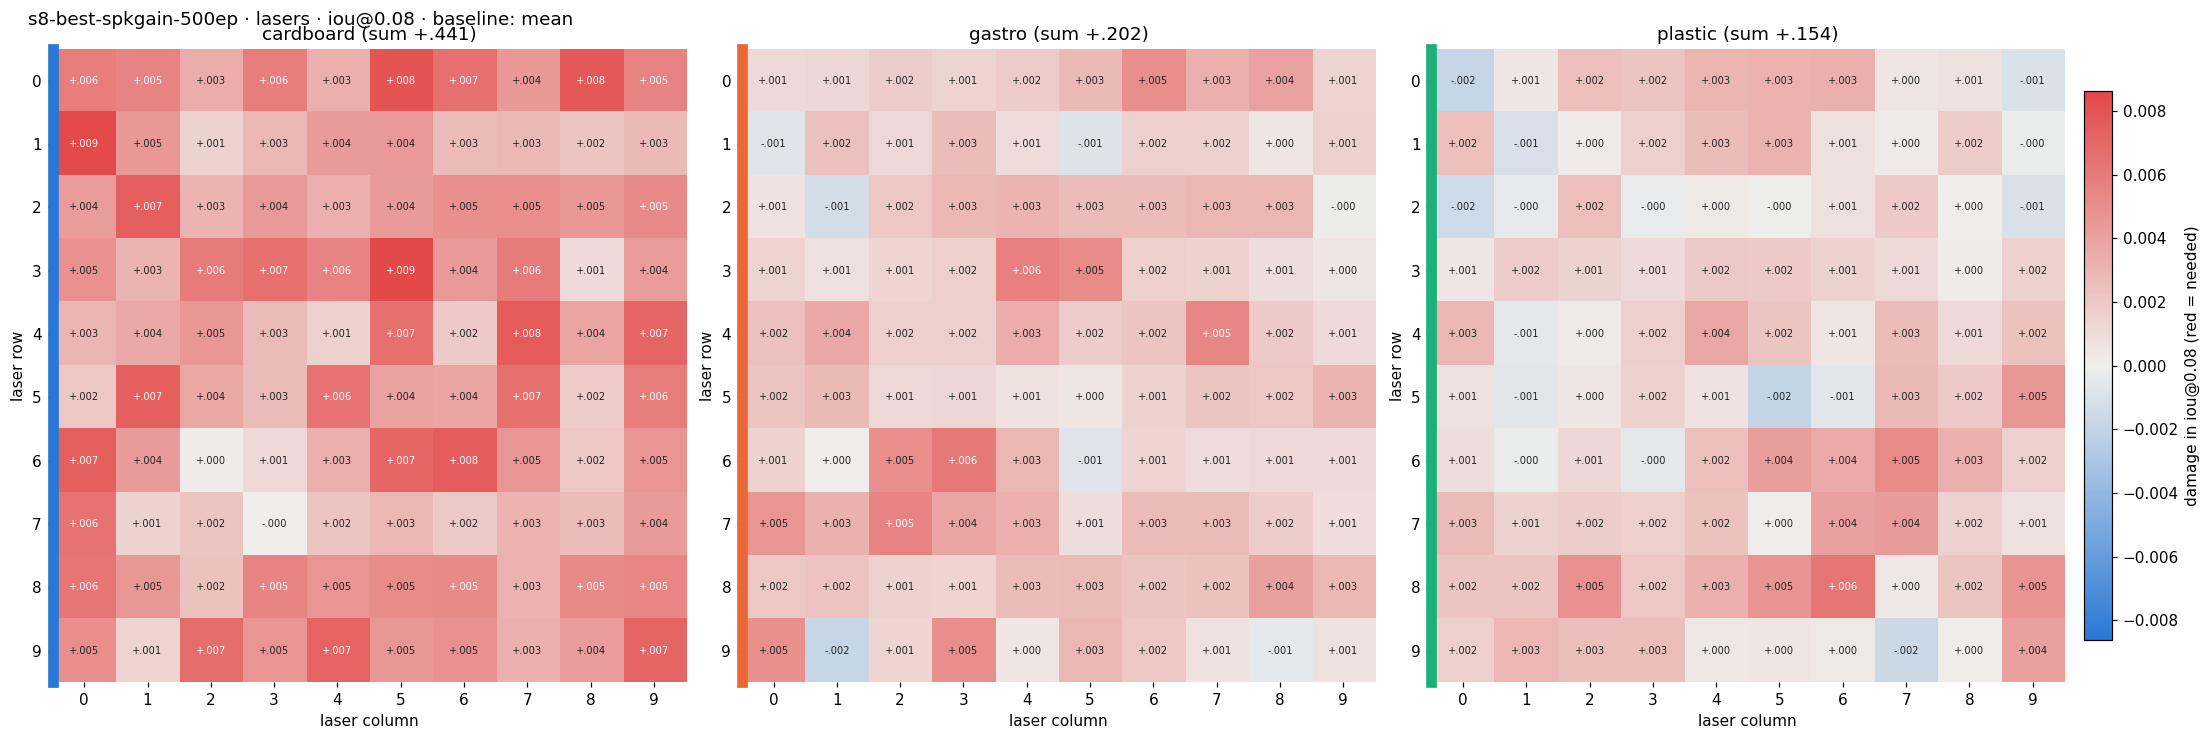

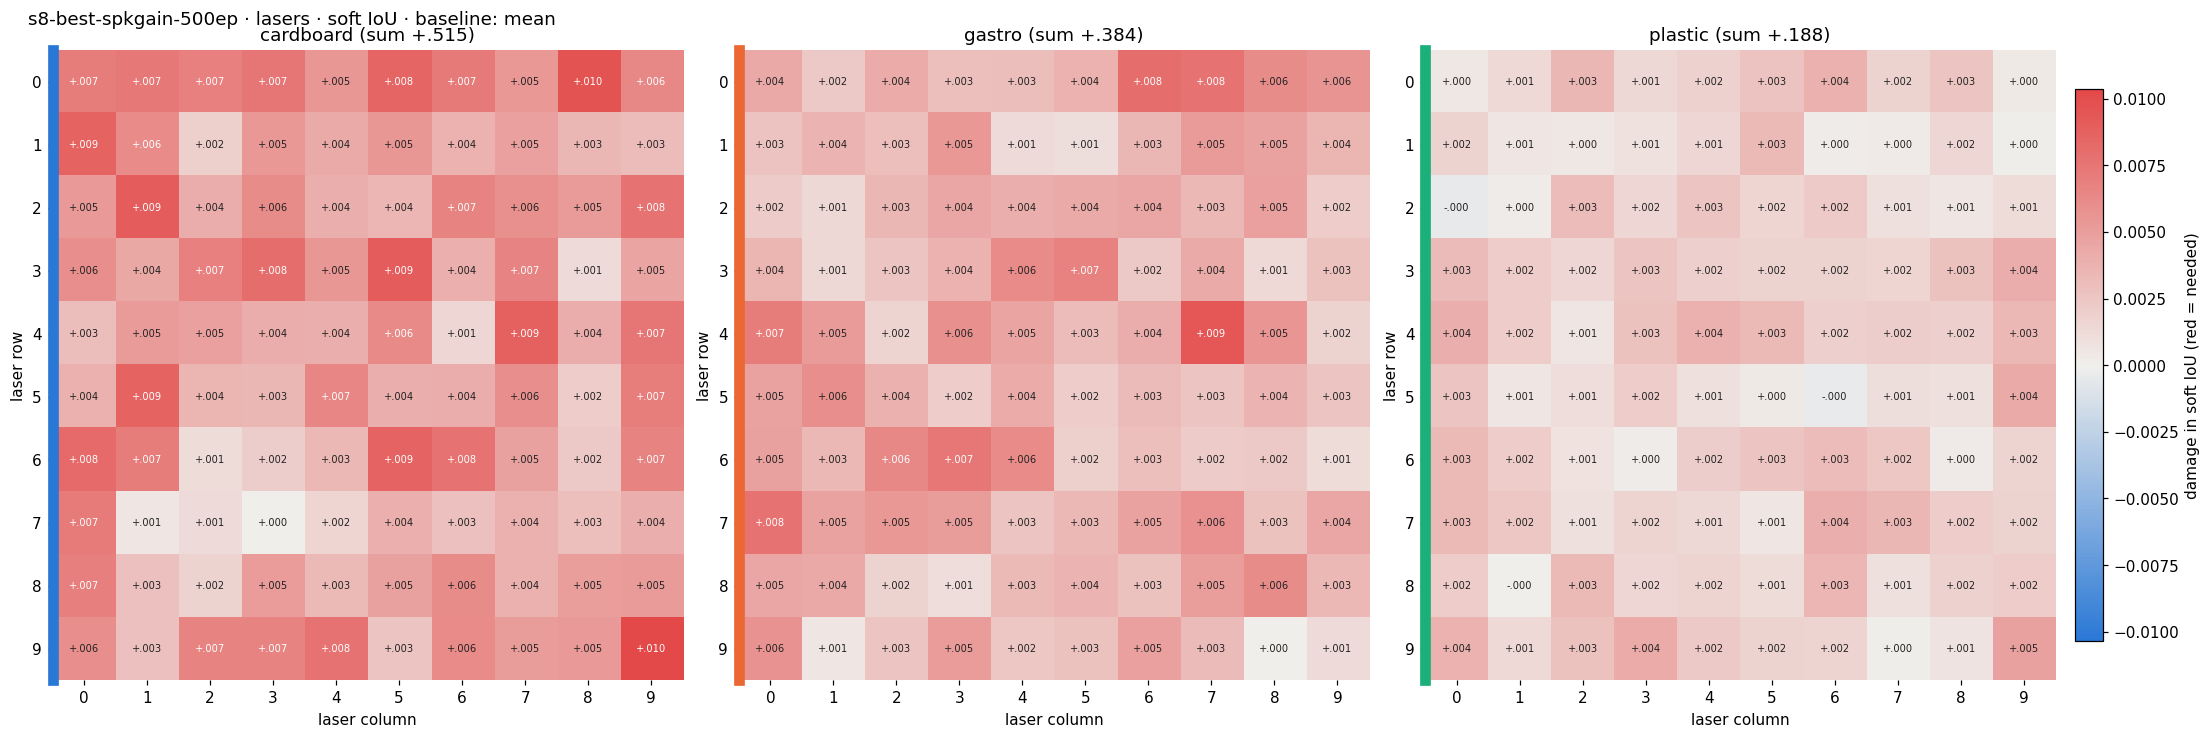

In [ ]:
def laser_figure(base, metric):
    D = I[base]; k = D['metrics'].index(metric); s, f, lab = UNIT[metric]
    V = D['laser'][k].numpy().reshape(nb, rows, cols) * s; lim = np.nanmax(np.abs(V))
    curves = 'curves' in D
    fig, axs = plt.subplots(2 if curves else 1, nb, figsize=(20, 10.5 if curves else 6.5), height_ratios=[1.5, 1] if curves else None, layout='constrained', squeeze=False)
    for b, bn in enumerate(boxes):
        im = heat(axs[0, b], V[b], lim, f, fs=6.5); tag(axs[0, b], b); axs[0, b].set_title(f'{bn} (sum {fmt(np.nansum(V[b]), f)})')
        axs[0, b].set_xticks(range(cols)); axs[0, b].set_yticks(range(rows)); axs[0, b].set_xlabel('laser column'); axs[0, b].set_ylabel('laser row')
        if curves: topk(axs[1, b], D, 'laser', k, b, s, legend=b == 0); axs[1, b].set_ylabel(lab)
    fig.colorbar(im, ax=axs[0], shrink=.85, pad=.01, label=f'damage in {lab} (red = needed)')
    fig.suptitle(f'{RUN} · lasers · {lab} · baseline: {base}', x=.01, ha='left', fontsize=12); plt.show()

for metric in d['metrics']:
    for base in BASELINES:
        if metric in I[base]['metrics']: laser_figure(base, metric)

## 3 · Laser × frequency: one laser in one band taken away
Every (laser, band) pair occluded alone: 1900 occlusions on 200 samples per box, scored by soft IoU. There are three views of the same numbers, for each baseline:
1. **All lasers × all bands**: rows are the 100 lasers in grid order, columns the 19 bands.
2. **One wall per band**: 19 small 10 × 10 laser grids, one per band (low → high). Each grid shows how much each laser matters *in that band*. The scale is shared by all 19 panels of a box.
3. **A wall of spectra**: the 10 × 10 grid where each laser's cell is a strip of its 19 bands.

**Caveat:** one cell is a tiny change measured on 200 samples, so most cells are at the noise level. The colour is clipped at the 99.5th percentile of |damage|.

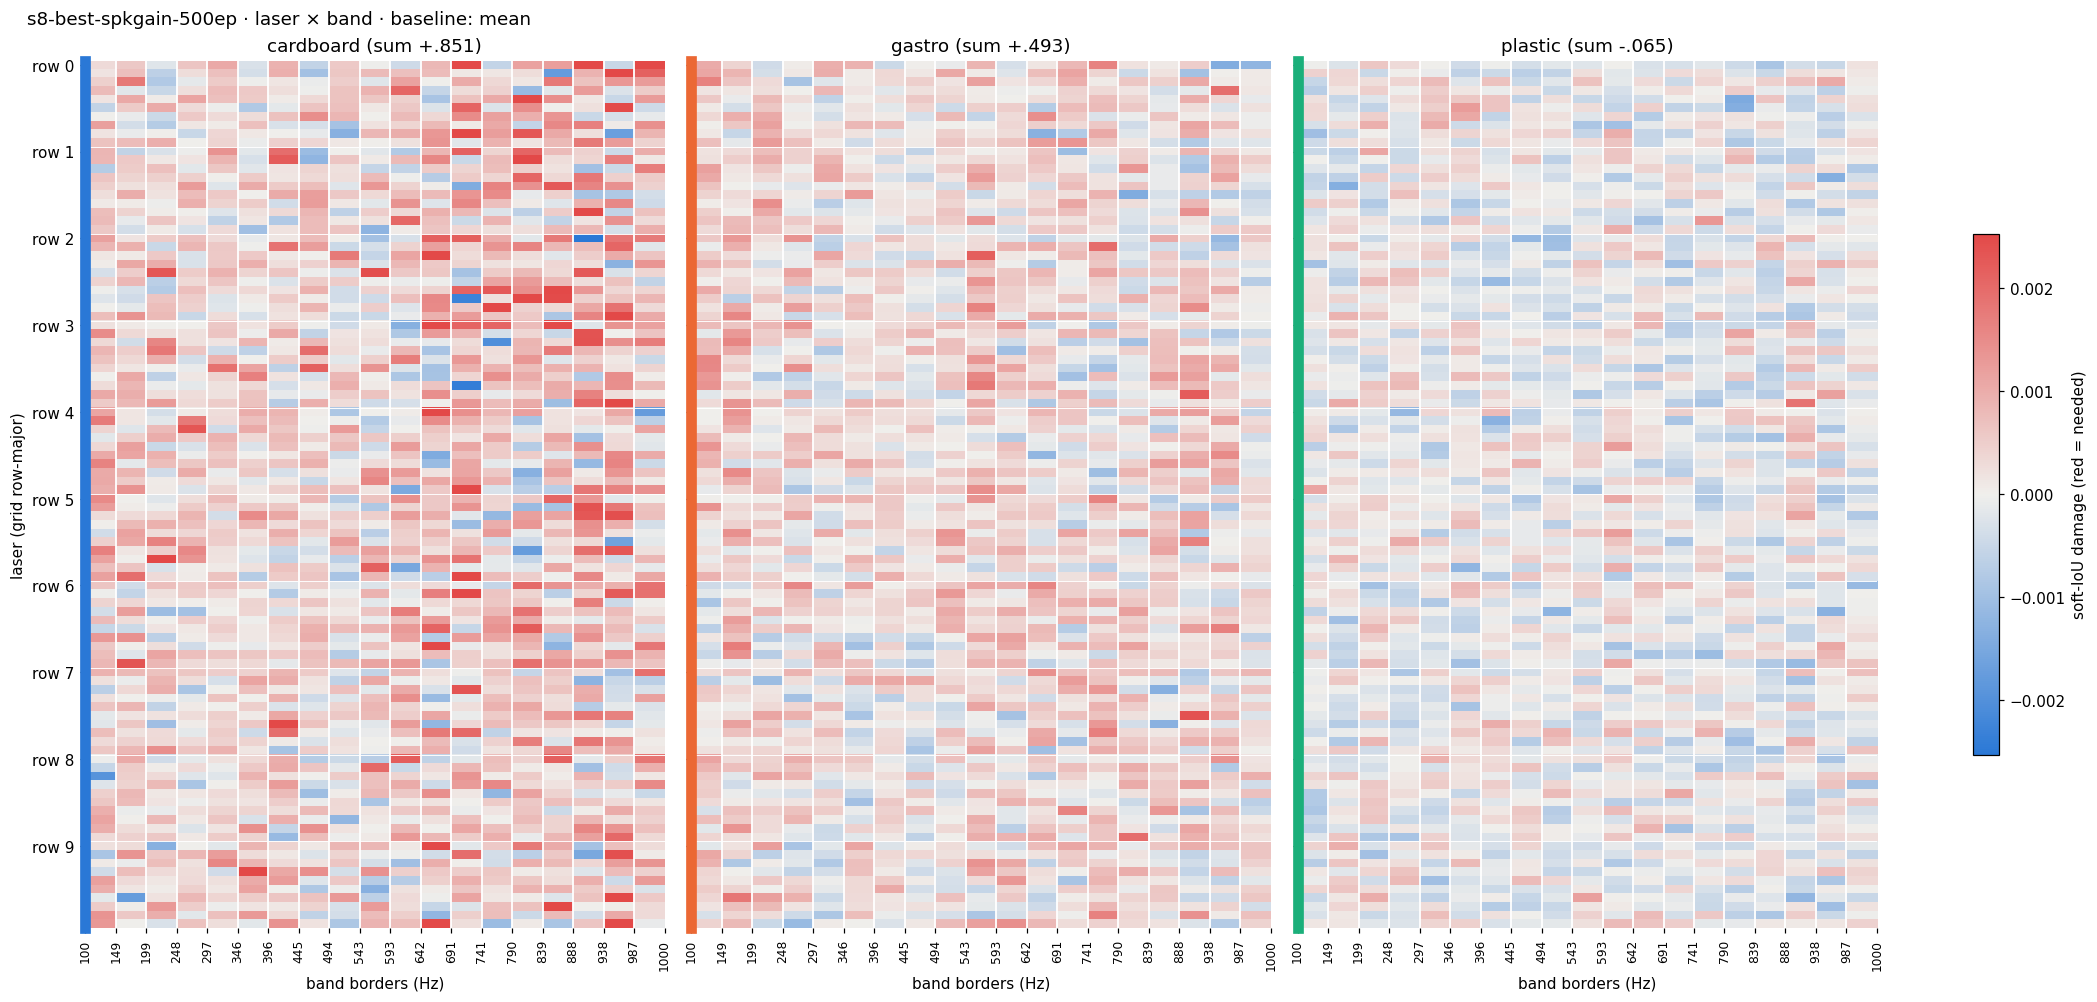

In [ ]:
SOFT = d['metrics'].index('soft_iou')
for base in BASELINES:
    J = I[base]['joint'][SOFT].numpy(); lim = np.nanpercentile(np.abs(J), 99.5)
    fig, axs = plt.subplots(1, nb, figsize=(19, 9), sharey=True, layout='constrained')
    for b, (ax, bn, m) in enumerate(zip(axs, boxes, J)):
        im = heat(ax, m, lim, annotate=False, aspect='auto'); band_axis(ax); tag(ax, b); ax.tick_params(axis='x', labelrotation=90)
        ax.set_yticks(range(0, 100, 10), [f'row {r}' for r in range(rows)]); ax.set_title(f'{bn} (sum {fmt(m.sum())})')
        for r in range(1, rows): ax.axhline(r * cols - .5, color='white', lw=.6)
    axs[0].set_ylabel('laser (grid row-major)'); [ax.set_xlabel('band borders (Hz)') for ax in axs]
    fig.colorbar(im, ax=axs, shrink=.6, label='soft-IoU damage (red = needed)'); fig.suptitle(f'{RUN} · laser × band · baseline: {base}', x=.01, ha='left', fontsize=12); plt.show()

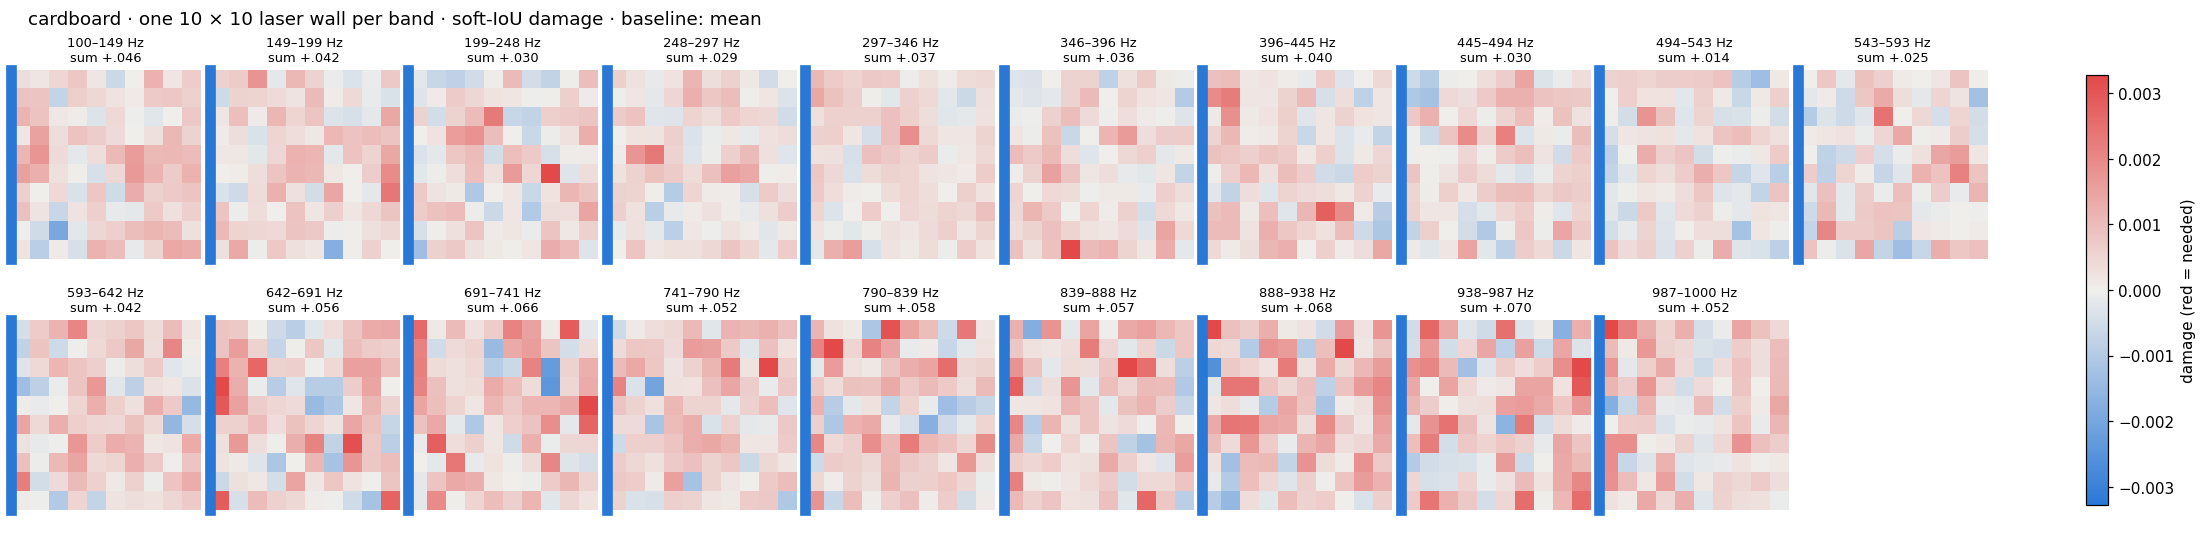

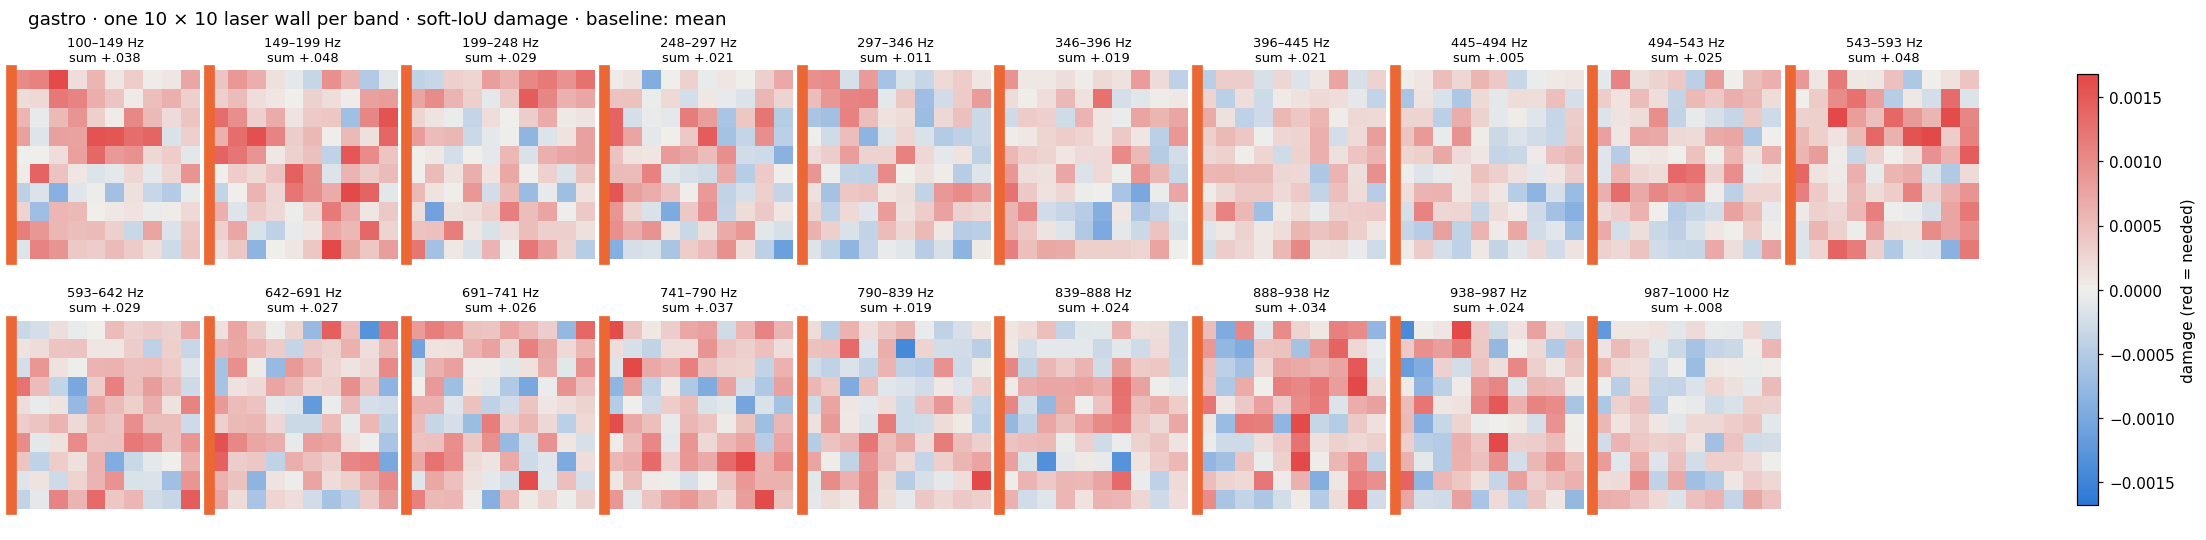

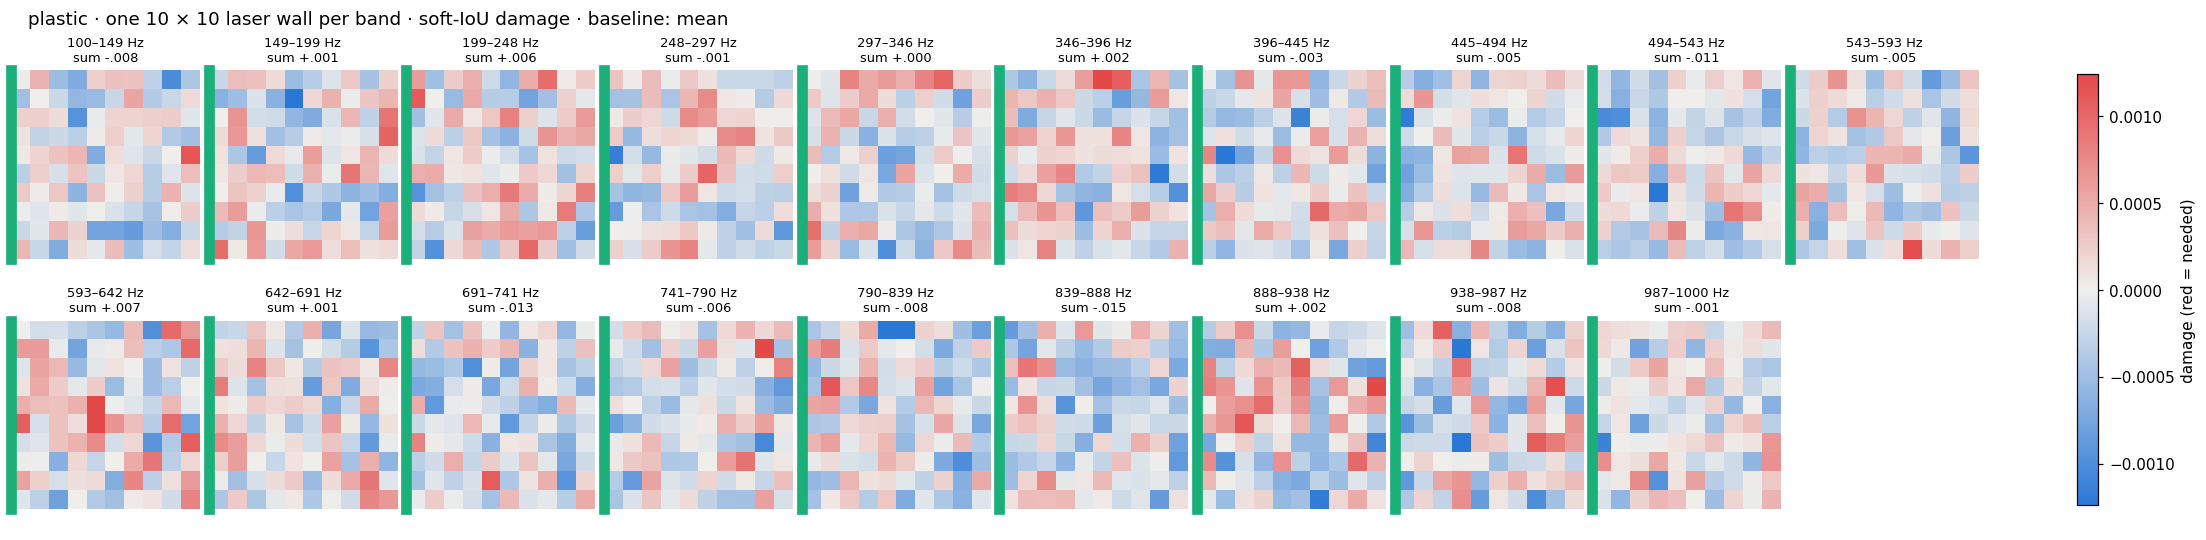

In [ ]:
for base in BASELINES:
    J = I[base]['joint'][SOFT].numpy()
    for b, bn in enumerate(boxes):
        m = J[b].reshape(rows, cols, P); lim = np.nanpercentile(np.abs(m), 99.5)
        fig, axs = plt.subplots(2, 10, figsize=(20, 4.8), layout='constrained')
        for j, ax in enumerate(axs.flat):
            ax.set_xticks([]); ax.set_yticks([])
            if j >= P: ax.axis('off'); continue
            im = heat(ax, m[..., j], lim, annotate=False); tag(ax, b); ax.set_title(f'{band_range(j)}\nsum {fmt(m[..., j].sum())}', fontsize=8.5)
        fig.suptitle(f'{bn} · one 10 × 10 laser wall per band · soft-IoU damage · baseline: {base}', x=.01, ha='left')
        fig.colorbar(im, ax=axs, shrink=.9, label='damage (red = needed)'); plt.show()

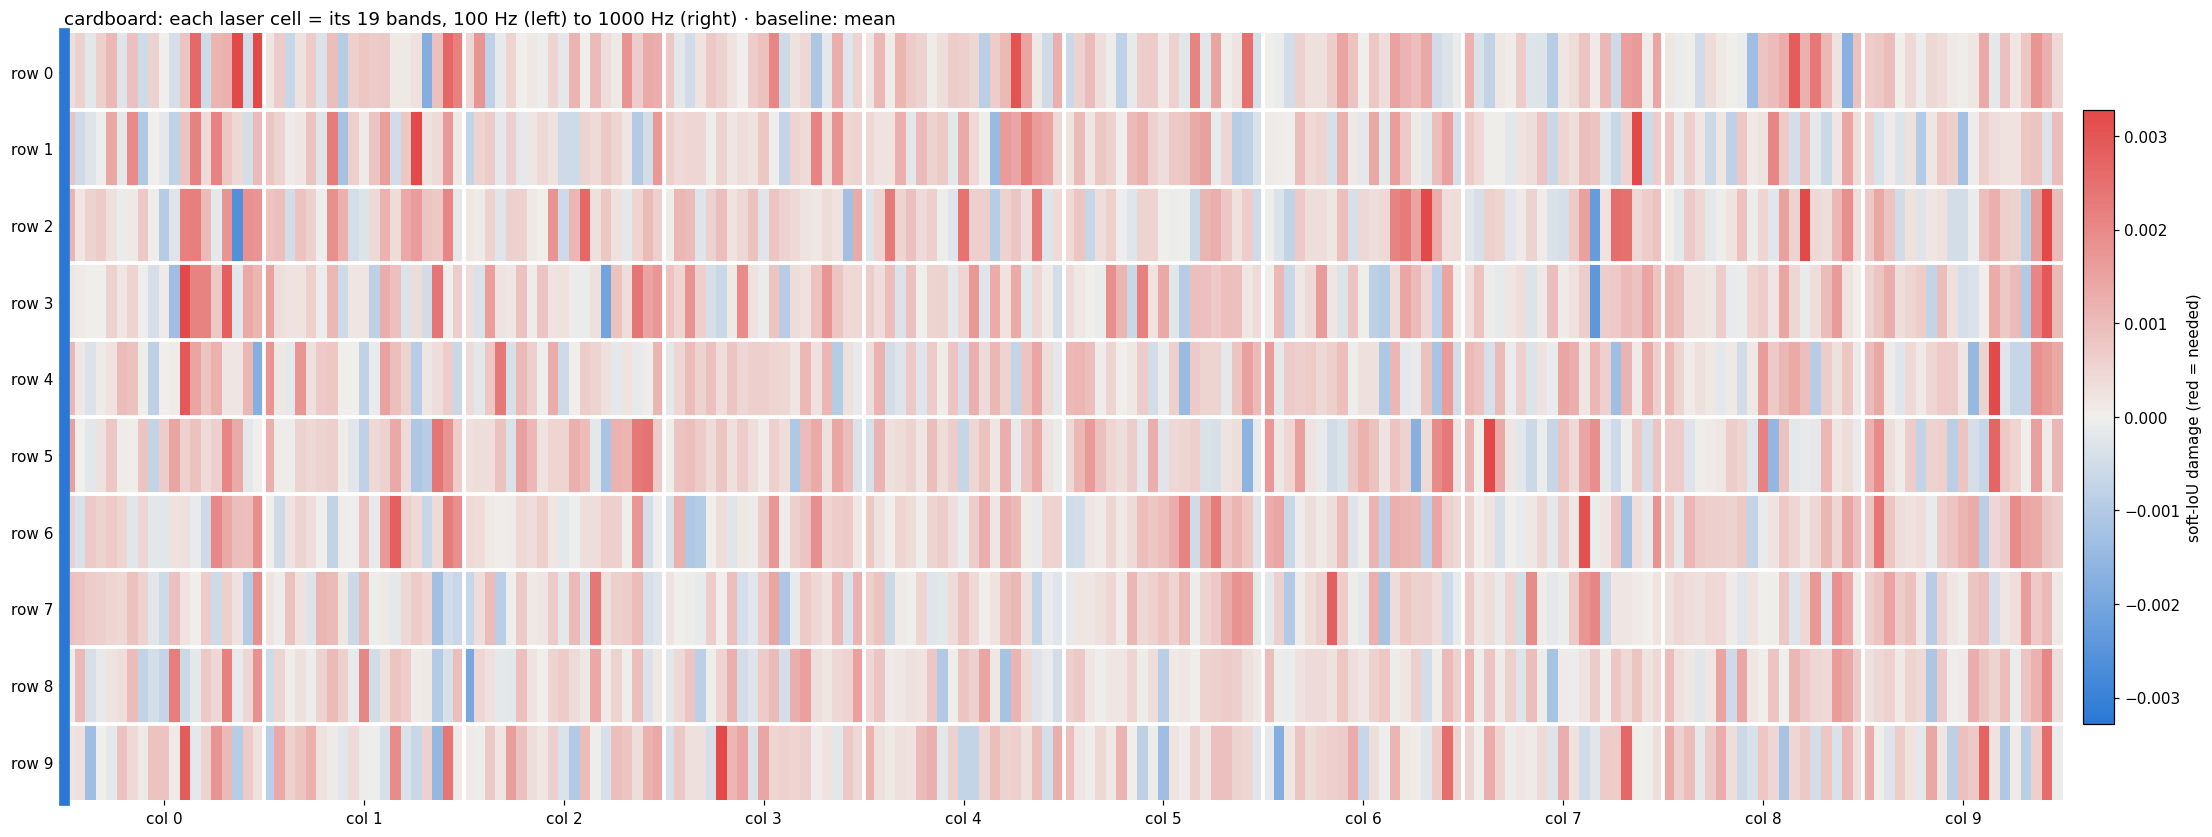

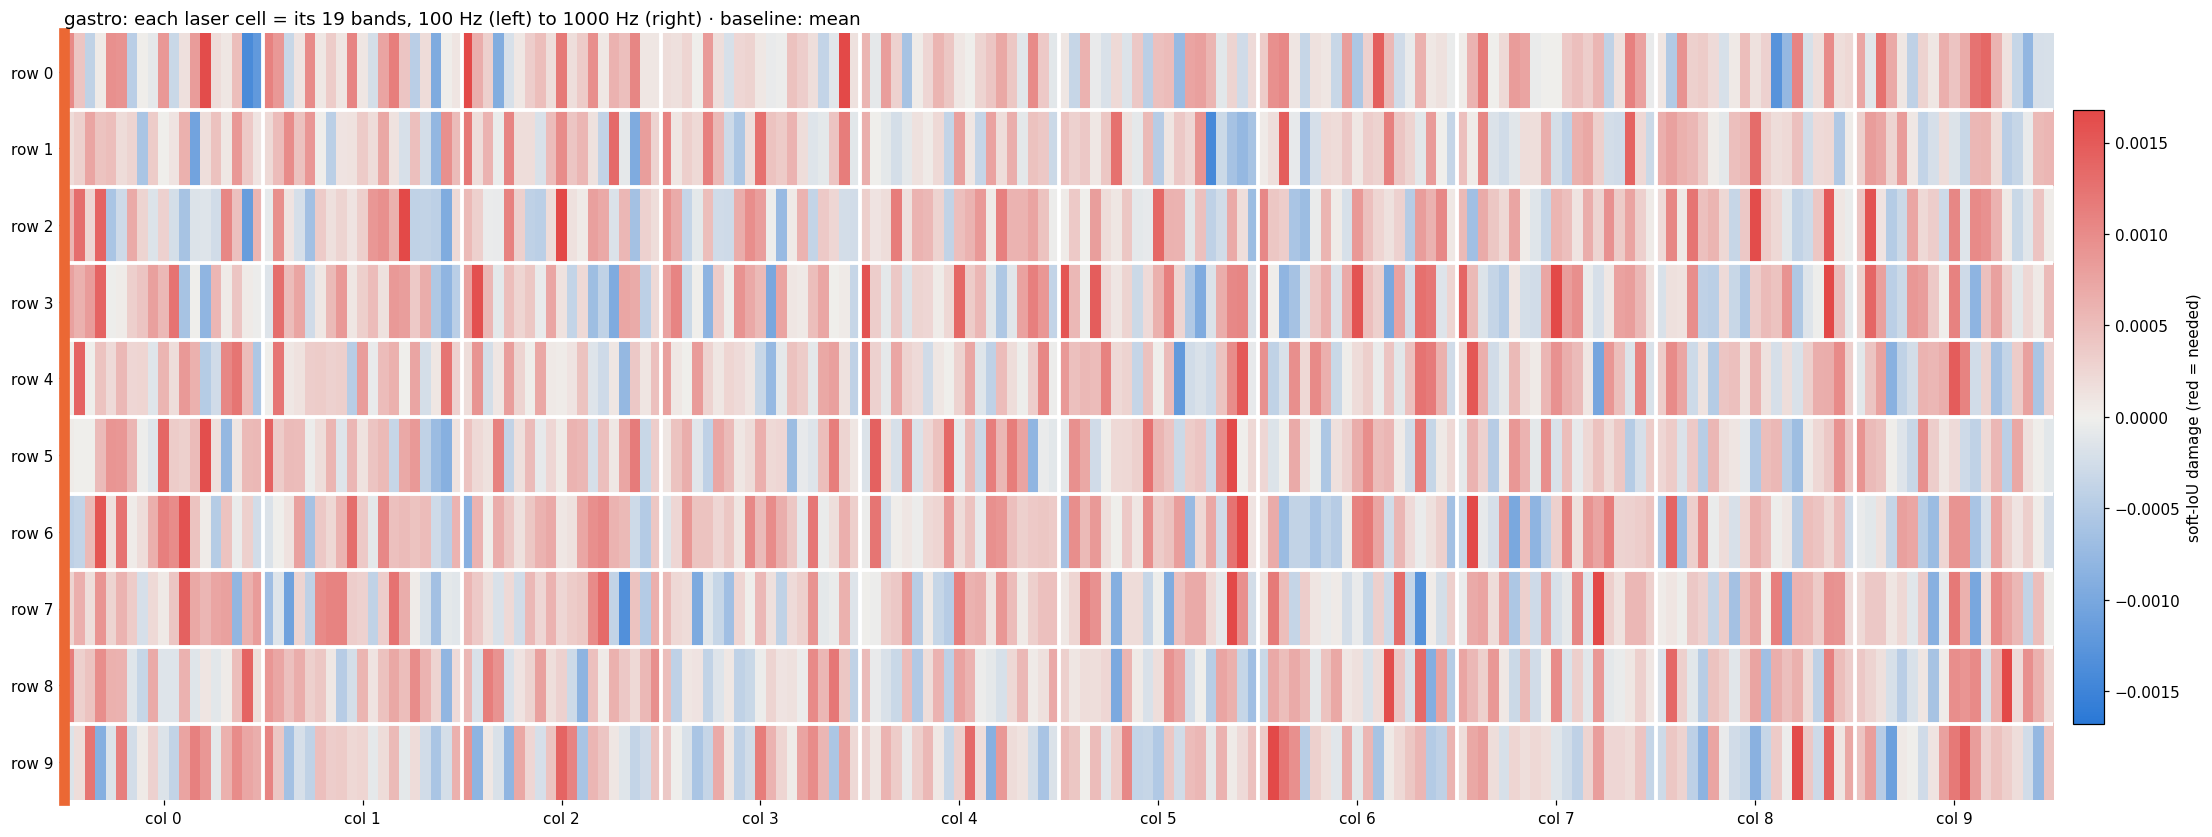

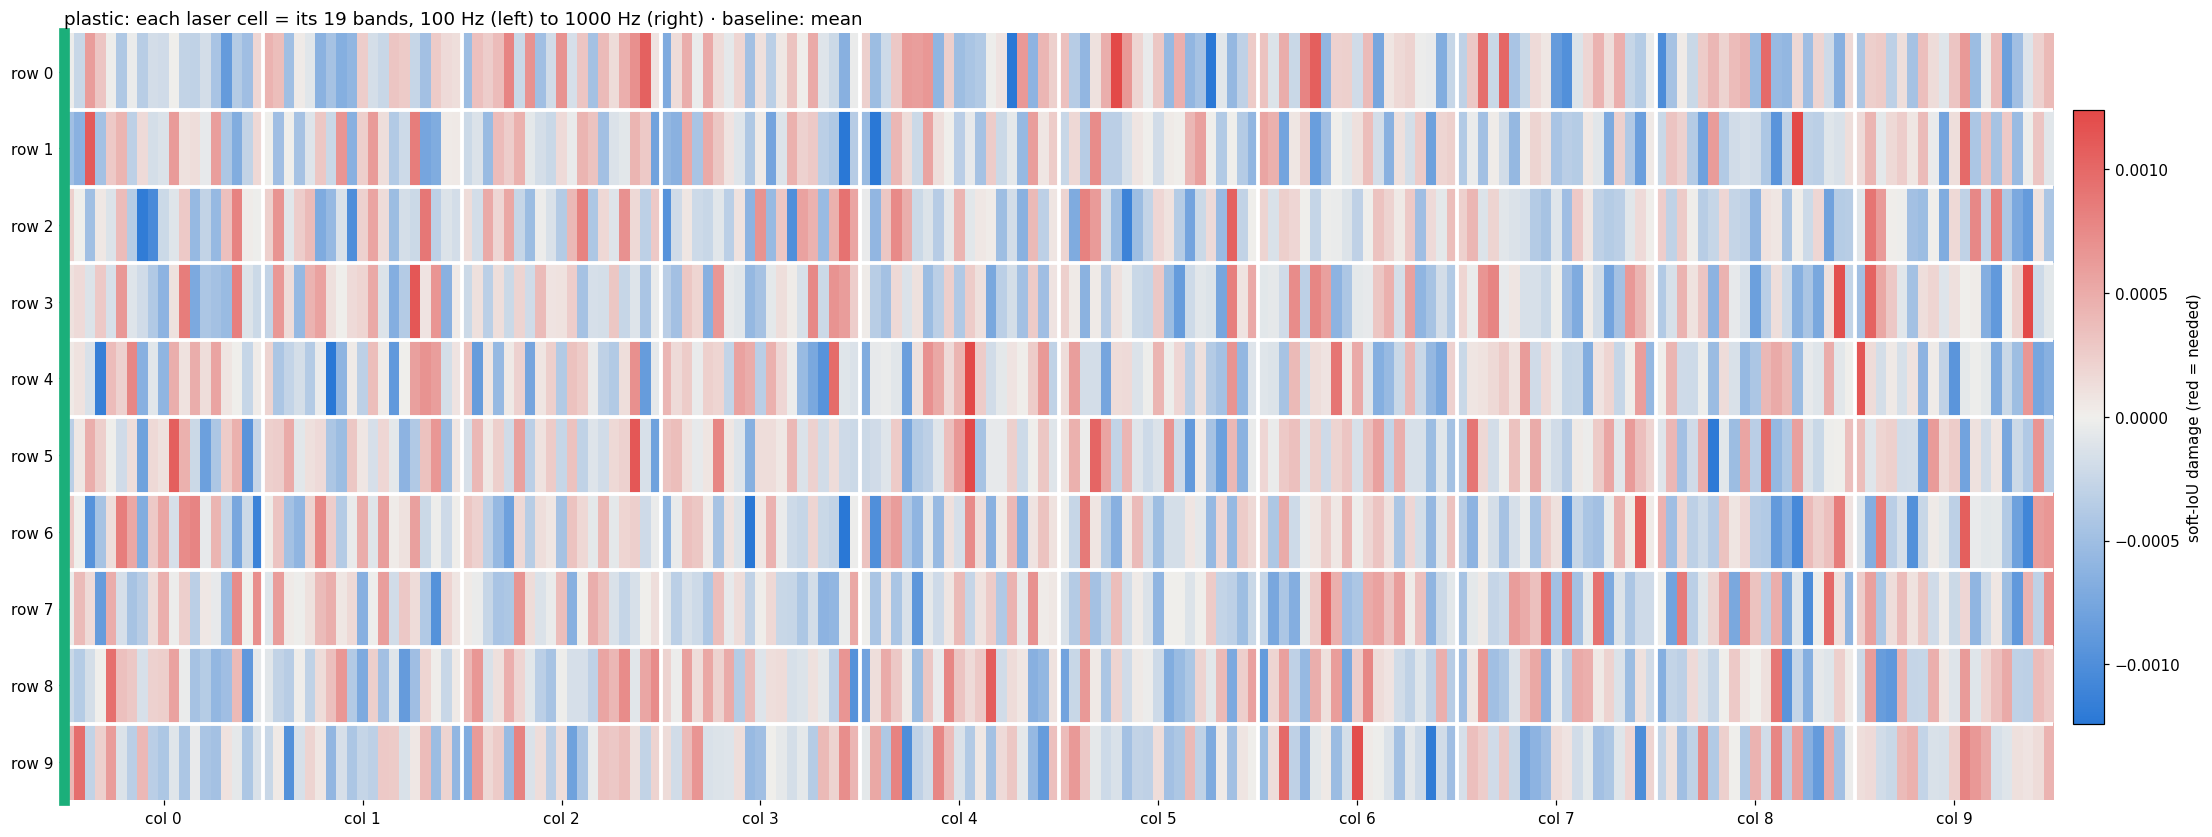

In [ ]:
for base in BASELINES:
    J = I[base]['joint'][SOFT].numpy()
    for b, bn in enumerate(boxes):
        m = J[b].reshape(rows, cols, P); lim = np.nanpercentile(np.abs(m), 99.5)
        fig, ax = plt.subplots(figsize=(20, 7.5), layout='constrained')
        im = heat(ax, m.reshape(rows, cols * P), lim, annotate=False, aspect='auto'); tag(ax, b)   # (row, col * band): each laser's bands side by side
        for c in range(1, cols): ax.axvline(c * P - .5, color='white', lw=2.5)
        for r in range(1, rows): ax.axhline(r - .5, color='white', lw=2.5)
        ax.set_xticks(np.arange(cols) * P + (P - 1) / 2, [f'col {c}' for c in range(cols)]); ax.set_yticks(range(rows), [f'row {r}' for r in range(rows)])
        ax.set_title(f'{bn}: each laser cell = its 19 bands, {EDGES[0]:.0f} Hz (left) to {EDGES[-1]:.0f} Hz (right) · baseline: {base}', loc='left')
        fig.colorbar(im, ax=ax, shrink=.8, pad=.01, label='soft-IoU damage (red = needed)'); plt.show()

## 4 · Grad-CAM (jacobgil/pytorch-grad-cam)
The target layer is the frequency stem's last conv. Its output is one token per (laser, ~49 Hz band), so a CAM there is a laser × frequency map; the library upsamples it to 100 lasers × 1170 bins. The target is each sample's soft IoU with the true mask. Methods:
- **GradCAM**: channel weights from the mean gradient.
- **HiResCAM**: gradient × activation elementwise; provably faithful for this kind of head.
- **LayerCAM**: per-location positive gradients.

**How to read these:** CAMs are unsigned (they show what argues *for* the mask), and the library rescales every sample to [0, 1]. So they say *where*, not *how much*. They use the sequential colour scale, not the red/blue one, and should be compared with the occlusion maps by ranking (section 6), not by value.

In [ ]:
if CAM is None: print('gradcam.pt not computed yet (src8/gradcam.py runs in the queue)')
else:
    for meth in CAM['methods']:
        Bm = CAM[meth + '_band'].numpy()                                  # (nb,L,P)
        prof, wall = Bm.mean(1), Bm.mean(2).reshape(nb, rows, cols)       # per band (mean over lasers), per laser (mean over bands)
        fig = plt.figure(figsize=(20, 7.6), layout='constrained'); gs = fig.add_gridspec(2, nb, height_ratios=[.9, 2])
        ax = fig.add_subplot(gs[0, :]); im = heat(ax, prof, prof.max(), '{:.2f}', signed=False, aspect='auto'); band_axis(ax)
        ax.set_yticks(range(nb), boxes); ax.set_xlabel('band borders (Hz)'); fig.colorbar(im, ax=ax, pad=.01, label='mean CAM')
        for b, bn in enumerate(boxes):
            ax = fig.add_subplot(gs[1, b]); im = heat(ax, wall[b], wall.max(), '{:.2f}', fs=6.5, signed=False); tag(ax, b); ax.set_title(bn)
            ax.set_xticks(range(cols)); ax.set_yticks(range(rows))
        fig.colorbar(im, ax=fig.axes[-nb:], shrink=.8, pad=.01, label='mean CAM over bands')
        fig.suptitle(f'{RUN} · {meth}: per band (top) and per laser (bottom)', x=.01, ha='left', fontsize=12); plt.show()
    fig, axs = plt.subplots(1, nb, figsize=(20, 6.5), sharey=True, layout='constrained')
    for ax, bn, m in zip(axs, boxes, CAM['HiResCAM'].numpy()):
        im = ax.imshow(m, aspect='auto', cmap=SEQ, vmin=0, vmax=np.percentile(m, 99.5), extent=[bhz[0], bhz[-1], 99.5, -.5], interpolation='nearest')
        ax.set_title(f'{bn}'); ax.set_xlabel('frequency (Hz)')
    axs[0].set_ylabel('laser (grid row-major)'); fig.colorbar(im, ax=axs, shrink=.7, label='HiResCAM'); fig.suptitle('HiResCAM at full resolution (100 lasers × 1170 bins)', x=.01, ha='left'); plt.show()

gradcam.pt not computed yet (src8/gradcam.py runs in the queue)


## 5 · Integrated gradients at full resolution (100 lasers × 1170 bins)
Gradient-based like Grad-CAM, but on the input itself and with the box-mean baseline. Top: the |IG| profile per bin against the band occlusion (both normalized). Bottom: |IG| for every laser and bin. |IG| is unsigned, so it uses the sequential scale.

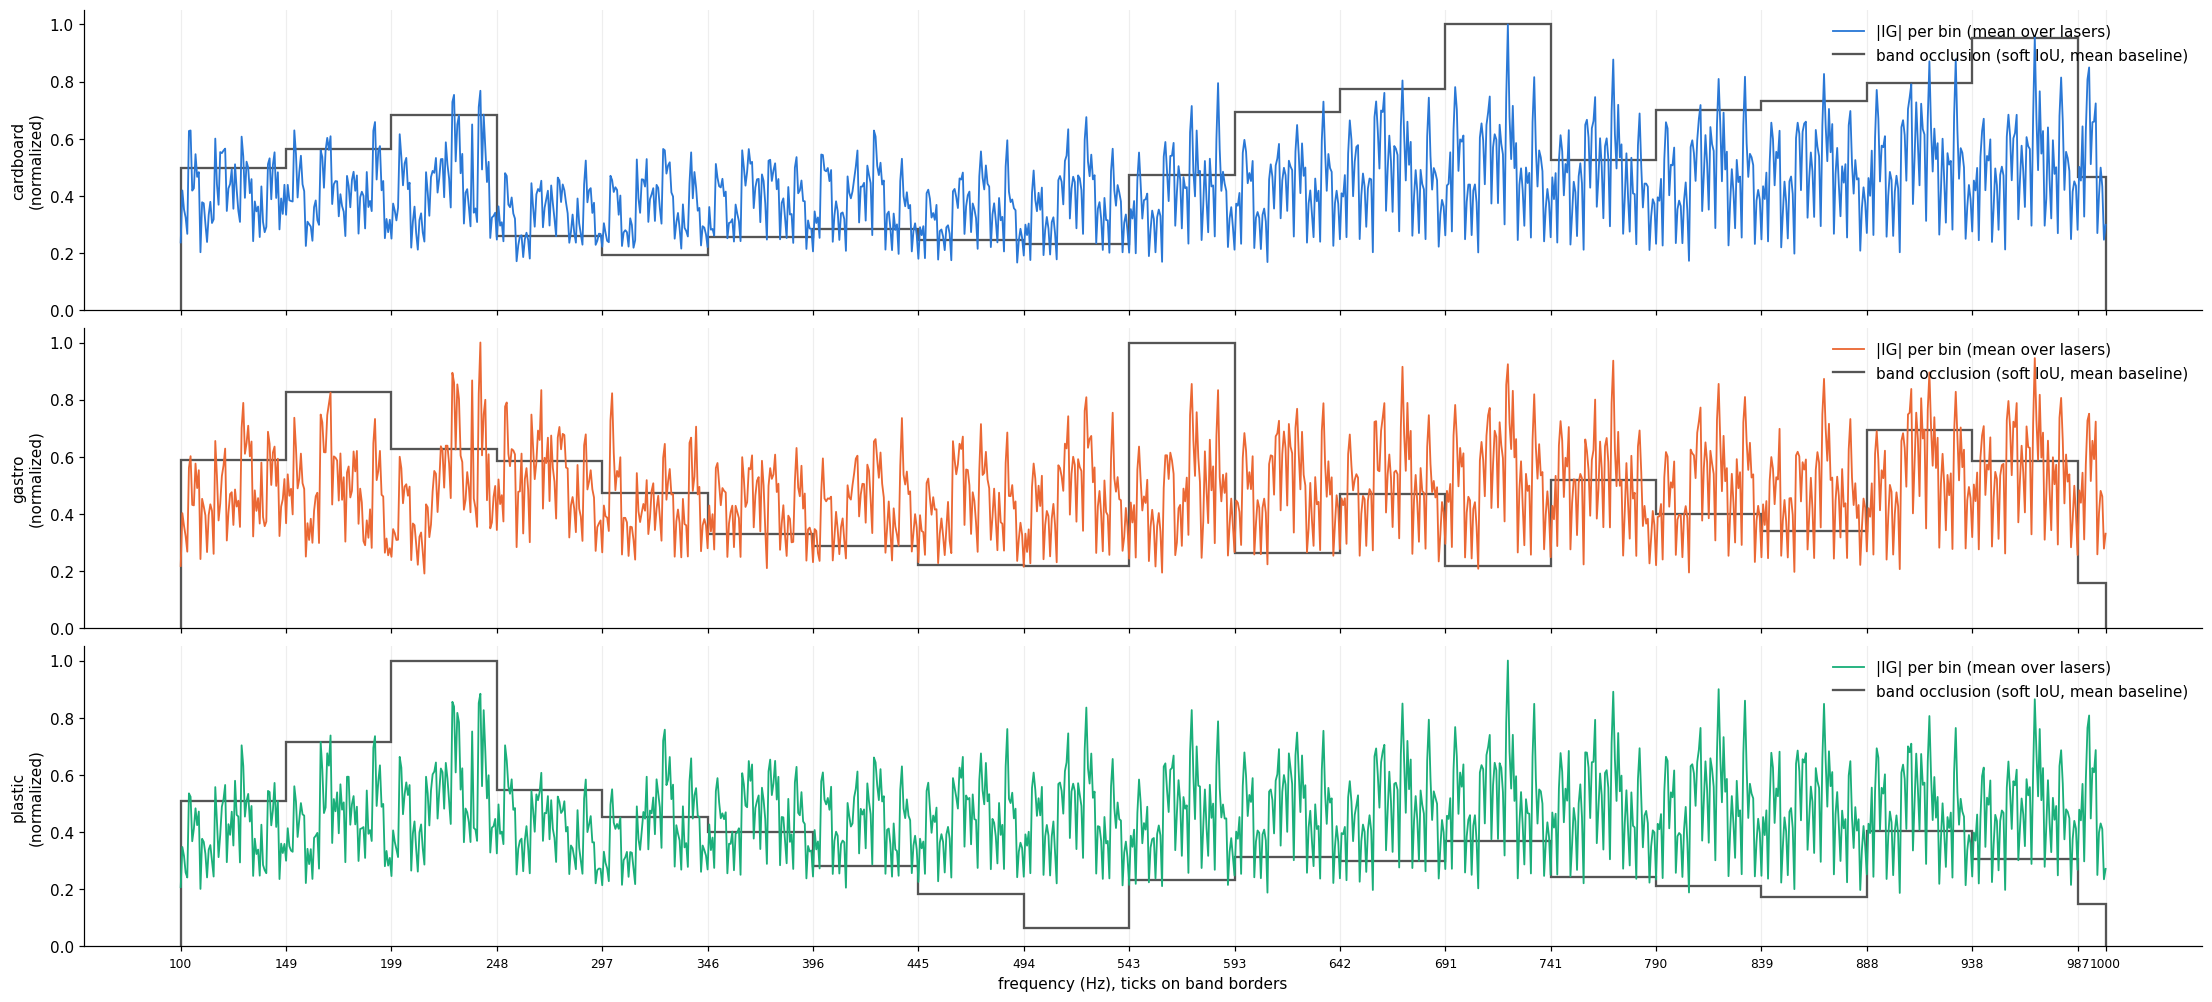

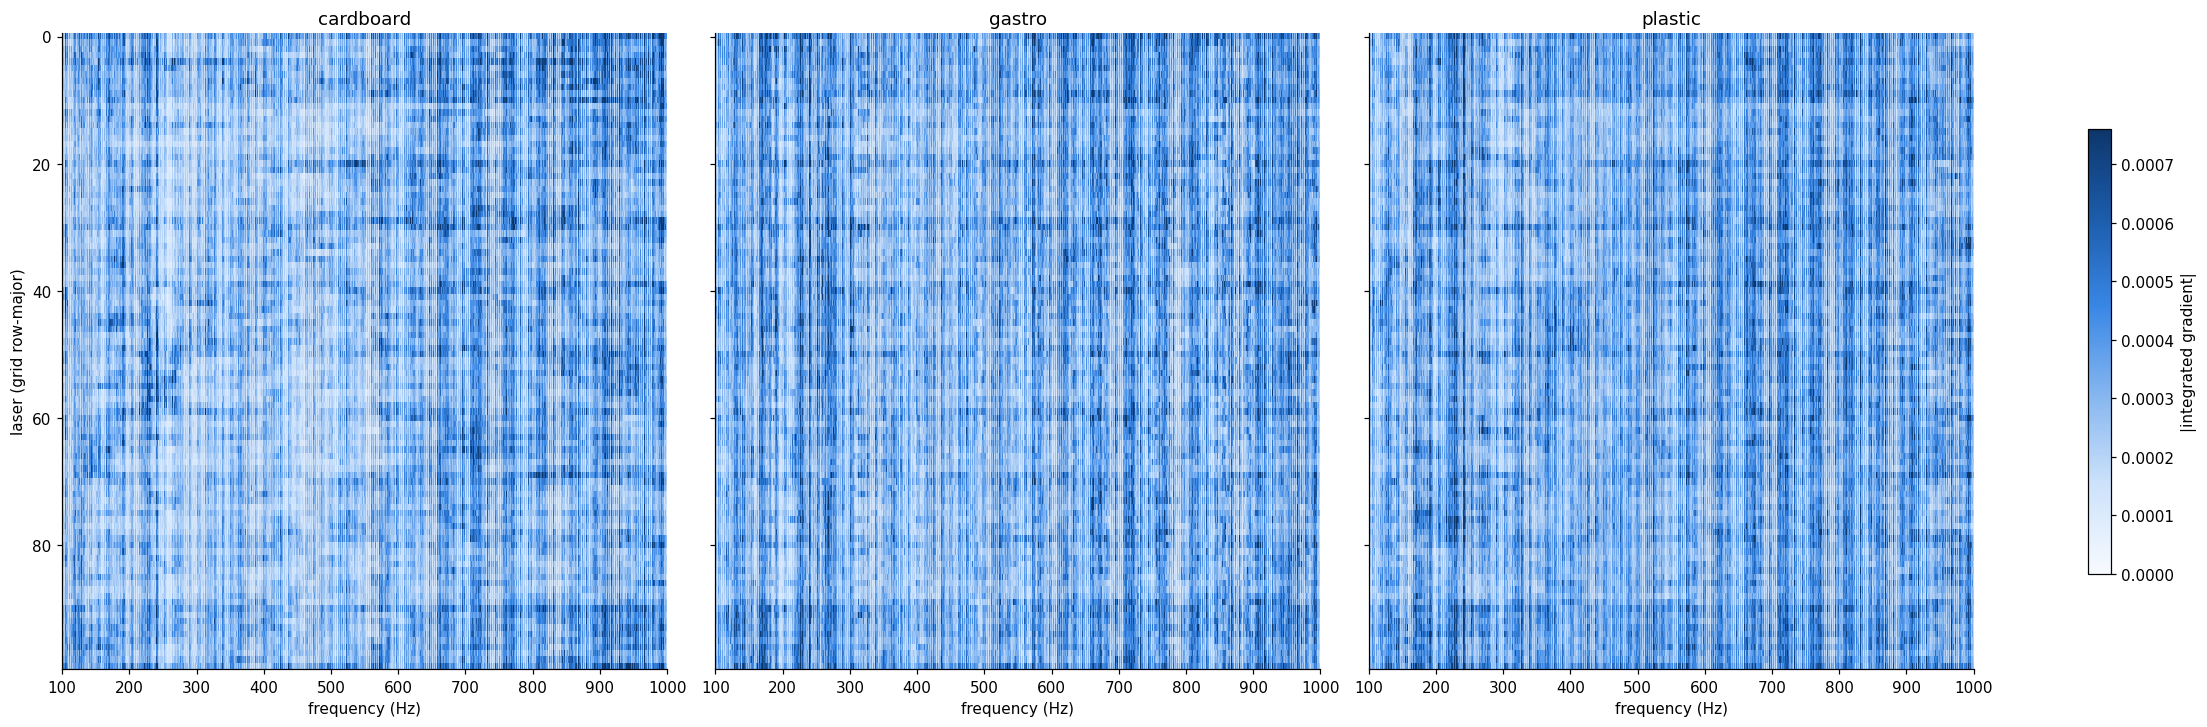

In [ ]:
ig = d['ig_abs'].numpy()
fig, axs = plt.subplots(nb, 1, figsize=(20, 3 * nb), sharex=True, layout='constrained')
for b, (ax, bn) in enumerate(zip(axs, boxes)):
    prof = ig[b].mean(0); ax.plot(bhz, prof / prof.max(), color=BOXC[b], lw=1.2, label='|IG| per bin (mean over lasers)')
    occ = d['band'][SOFT, b].numpy(); ax.stairs(occ / max(np.nanmax(occ), 1e-9), EDGES, color='#555', lw=1.5, label='band occlusion (soft IoU, mean baseline)')
    ax.set_ylabel(f'{bn}\n(normalized)'); ax.legend(frameon=False, loc='upper right'); ax.set_xticks(EDGES, [f'{e:.0f}' for e in EDGES], fontsize=8)
    for e in EDGES: ax.axvline(e, color='#eee', lw=.8, zorder=0)
axs[-1].set_xlabel('frequency (Hz), ticks on band borders'); plt.show()
fig, axs = plt.subplots(1, nb, figsize=(20, 6.5), sharey=True, layout='constrained')
for ax, bn, m in zip(axs, boxes, ig):
    im = ax.imshow(m, aspect='auto', cmap=SEQ, vmin=0, vmax=np.percentile(m, 99.5), extent=[bhz[0], bhz[-1], 99.5, -.5], interpolation='nearest')
    ax.set_title(bn); ax.set_xlabel('frequency (Hz)')
axs[0].set_ylabel('laser (grid row-major)'); fig.colorbar(im, ax=axs, shrink=.7, label='|integrated gradient|'); plt.show()

## 6 · Do the methods agree?
The Spearman rank correlation between every pair of importance estimates, per box: the bands (19) on the top row, the lasers (100) on the bottom. Occlusion uses soft IoU. The colour runs from −1 (blue) to +1 (red).

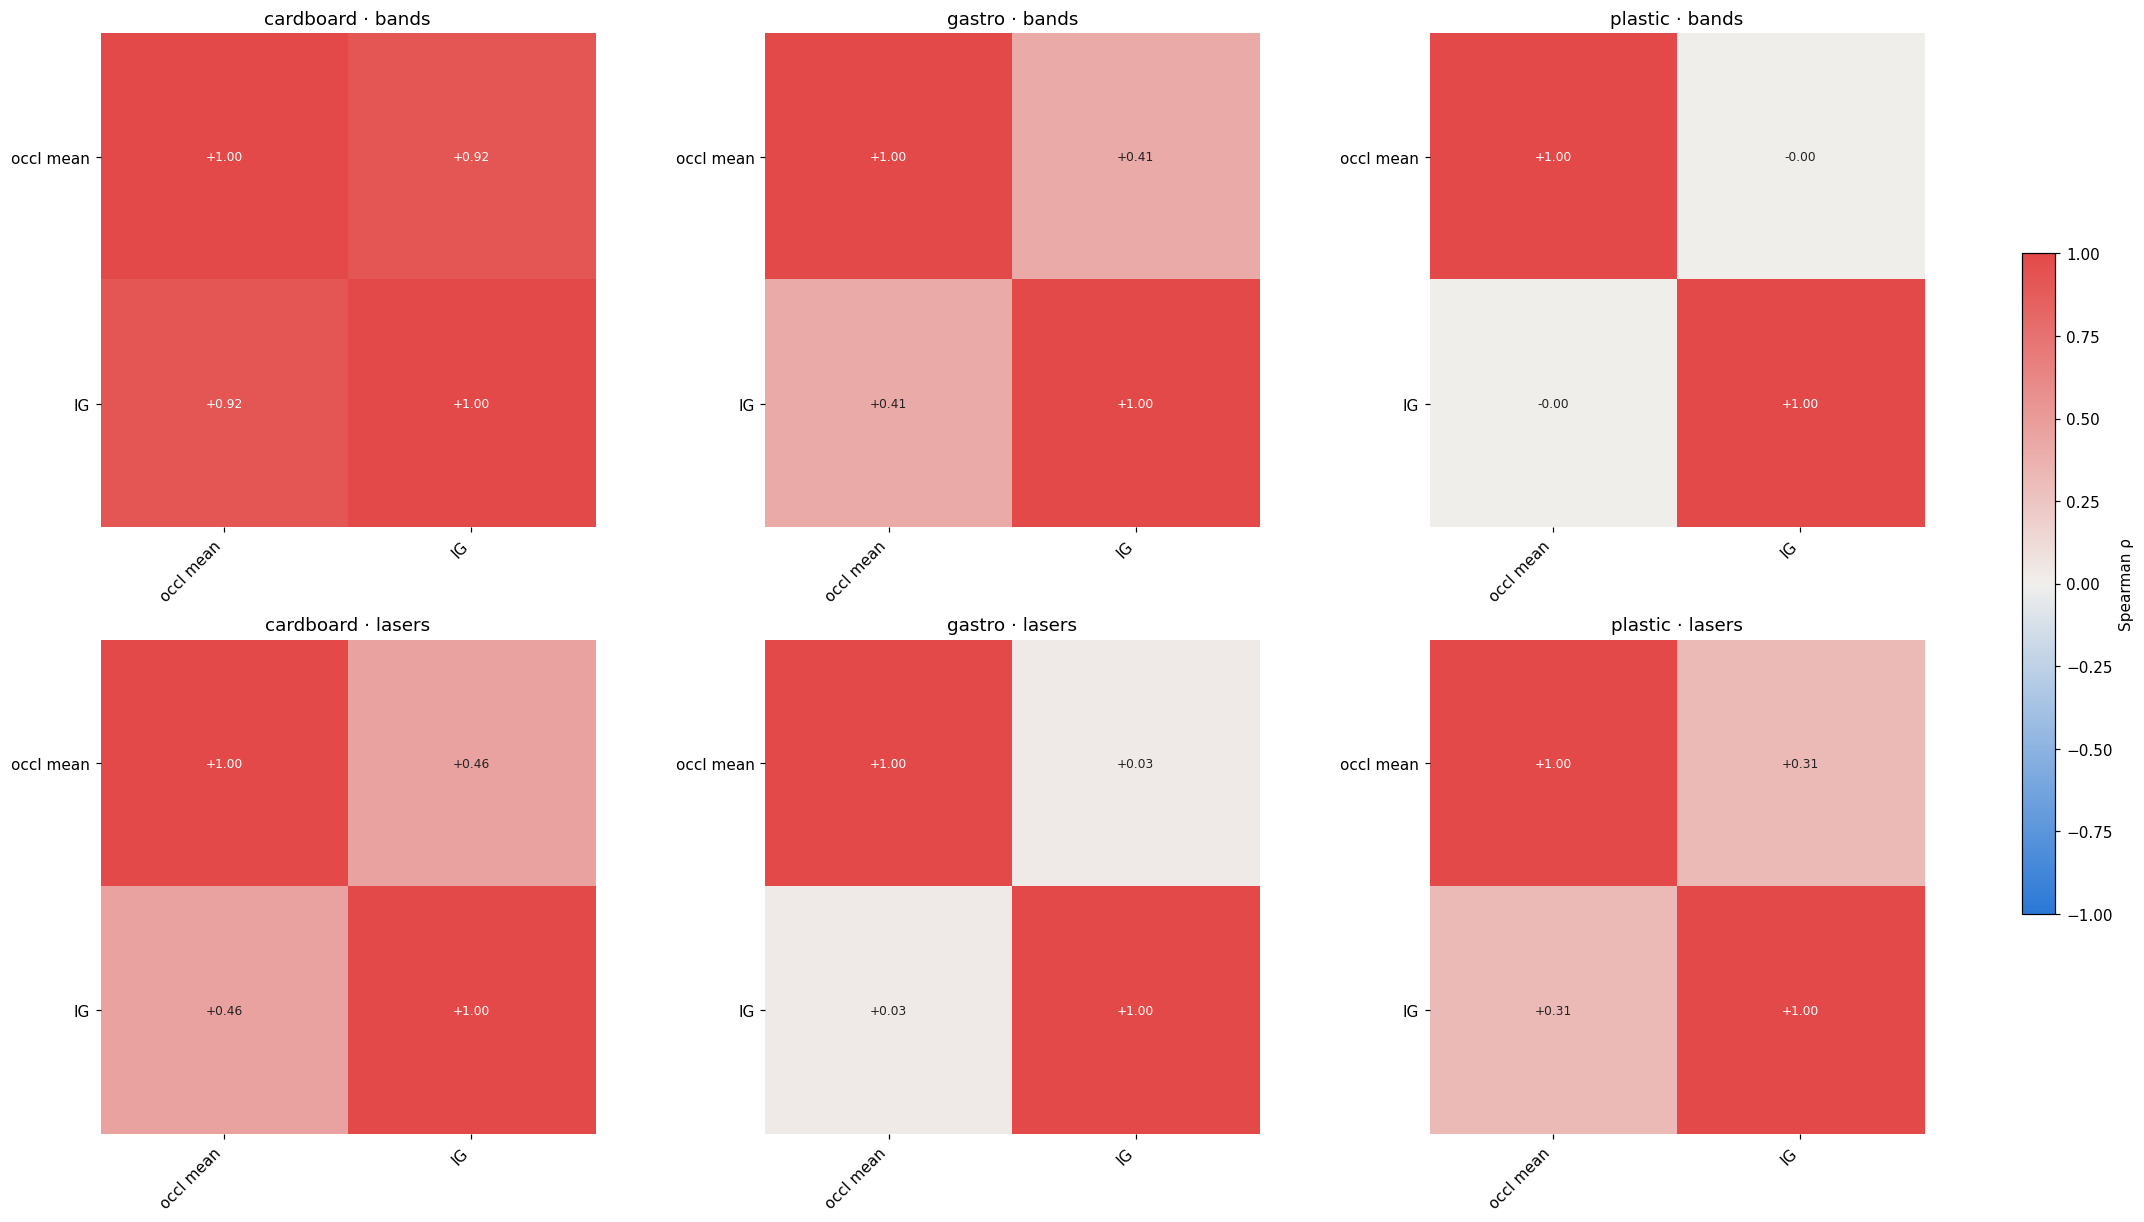

In [ ]:
def estimates(b):
    band, laser = {}, {}
    for base in BASELINES:
        band[f'occl {base}'], laser[f'occl {base}'] = I[base]['band'][SOFT, b].numpy(), I[base]['laser'][SOFT, b].numpy()
    band['IG'] = np.array([ig[b][:, j * BAND:(j + 1) * BAND].sum() for j in range(P)]); laser['IG'] = ig[b].sum(1)
    if CAM is not None:
        for meth in CAM['methods']: band[meth], laser[meth] = CAM[meth + '_band'][b].mean(0).numpy(), CAM[meth + '_band'][b].mean(1).numpy()
    return band, laser
fig, axs = plt.subplots(2, nb, figsize=(20, 11), layout='constrained')
for b, bn in enumerate(boxes):
    for r, est in enumerate(estimates(b)):
        names = list(est); R = np.array([[spearmanr(est[x], est[y]).statistic for y in names] for x in names])
        im = heat(axs[r, b], R, 1, '{:+.2f}', fs=8); axs[r, b].set_xticks(range(len(names)), names, rotation=45, ha='right'); axs[r, b].set_yticks(range(len(names)), names)
        axs[r, b].set_title(f'{bn} · {["bands", "lasers"][r]}')
fig.colorbar(im, ax=axs, shrink=.6, label='Spearman ρ'); plt.show()

## 7 · Log power vs magnitude input (s8-best-spkgain vs s8-best-mag)
The two runs differ only in the input signal. Does magnitude input change which bands the model reads? (Mean baseline, soft IoU.)

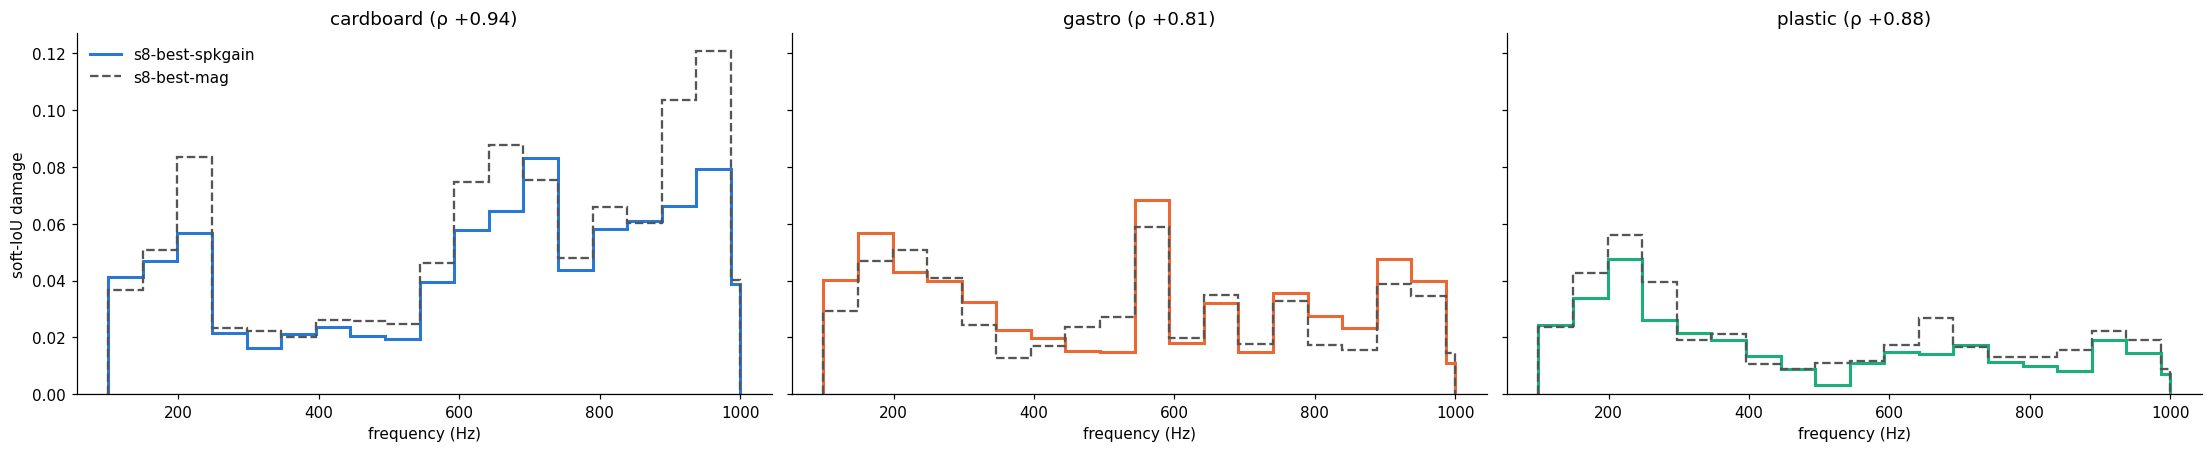

In [ ]:
J2 = load(COMPARE).get('mean')
if J2 is None: print(f'{COMPARE}: importance not computed yet')
else:
    fig, axs = plt.subplots(1, nb, figsize=(20, 4), sharey=True, layout='constrained')
    for b, (ax, bn) in enumerate(zip(axs, boxes)):
        b2 = [BOX_NAMES.get(x, x) for x in J2['boxes']].index(bn)
        ax.stairs(d['band'][SOFT, b], EDGES, color=BOXC[b], lw=2, label=RUN.replace('-500ep', ''))
        ax.stairs(J2['band'][J2['metrics'].index('soft_iou'), b2], EDGES, color='#555', lw=1.5, ls='--', label=COMPARE.replace('-500ep', ''))
        rho = spearmanr(d['band'][SOFT, b], J2['band'][J2['metrics'].index('soft_iou'), b2]).statistic
        ax.axhline(0, color='#888', lw=.8); ax.set_title(f'{bn} (ρ {rho:+.2f})'); ax.set_xlabel('frequency (Hz)')
    axs[0].set_ylabel('soft-IoU damage'); axs[0].legend(frameon=False); plt.show()

## 8 · Do the augmentations shape what the model reads?
Each step down this list adds one augmentation to the one before it, all else equal:

| run | adds | what the augmentation does |
|---|---|---|
| s8-posesum-contour | (no augmentation) | |
| s8-best-jitter | laser jitter 0.5 | the 10 × 10 laser field resampled at a grid shifted by up to ½ cell: each laser becomes a blend of its neighbours |
| s8-best-spkgain | speaker gain | a random smooth gain across frequency (~20 Hz scale): an unseen speaker |
| s8-best-mag | magnitude input | (not an augmentation; for reference) |
| s8-mag-fjit | frequency jitter 0.002 | the frequency axis stretched by up to ±0.2%: resonances move together (±0.2 Hz at 100 Hz, ±2 Hz at 1 kHz) |
| s8-mag-drop | laser and band dropout | up to 25% of lasers and of bands removed per sample |

Two questions:
1. **Importance:** does laser jitter make the laser importance diffuse? It blends neighbours, so neighbours become redundant. The statistics are the top-10 share, the edge share, and how smooth each map is: the correlation of each laser's importance with the mean of its four neighbours.
2. **Tolerance (`src8/shift_probe.py`):** shift every eval sample by a *fixed* amount (the laser grid by d cells, the frequency axis by ε) and score it. A model trained with jitter should stay flat over the range it was jittered on. The cost shows as precision it no longer resolves.

Only runs whose results exist are drawn.

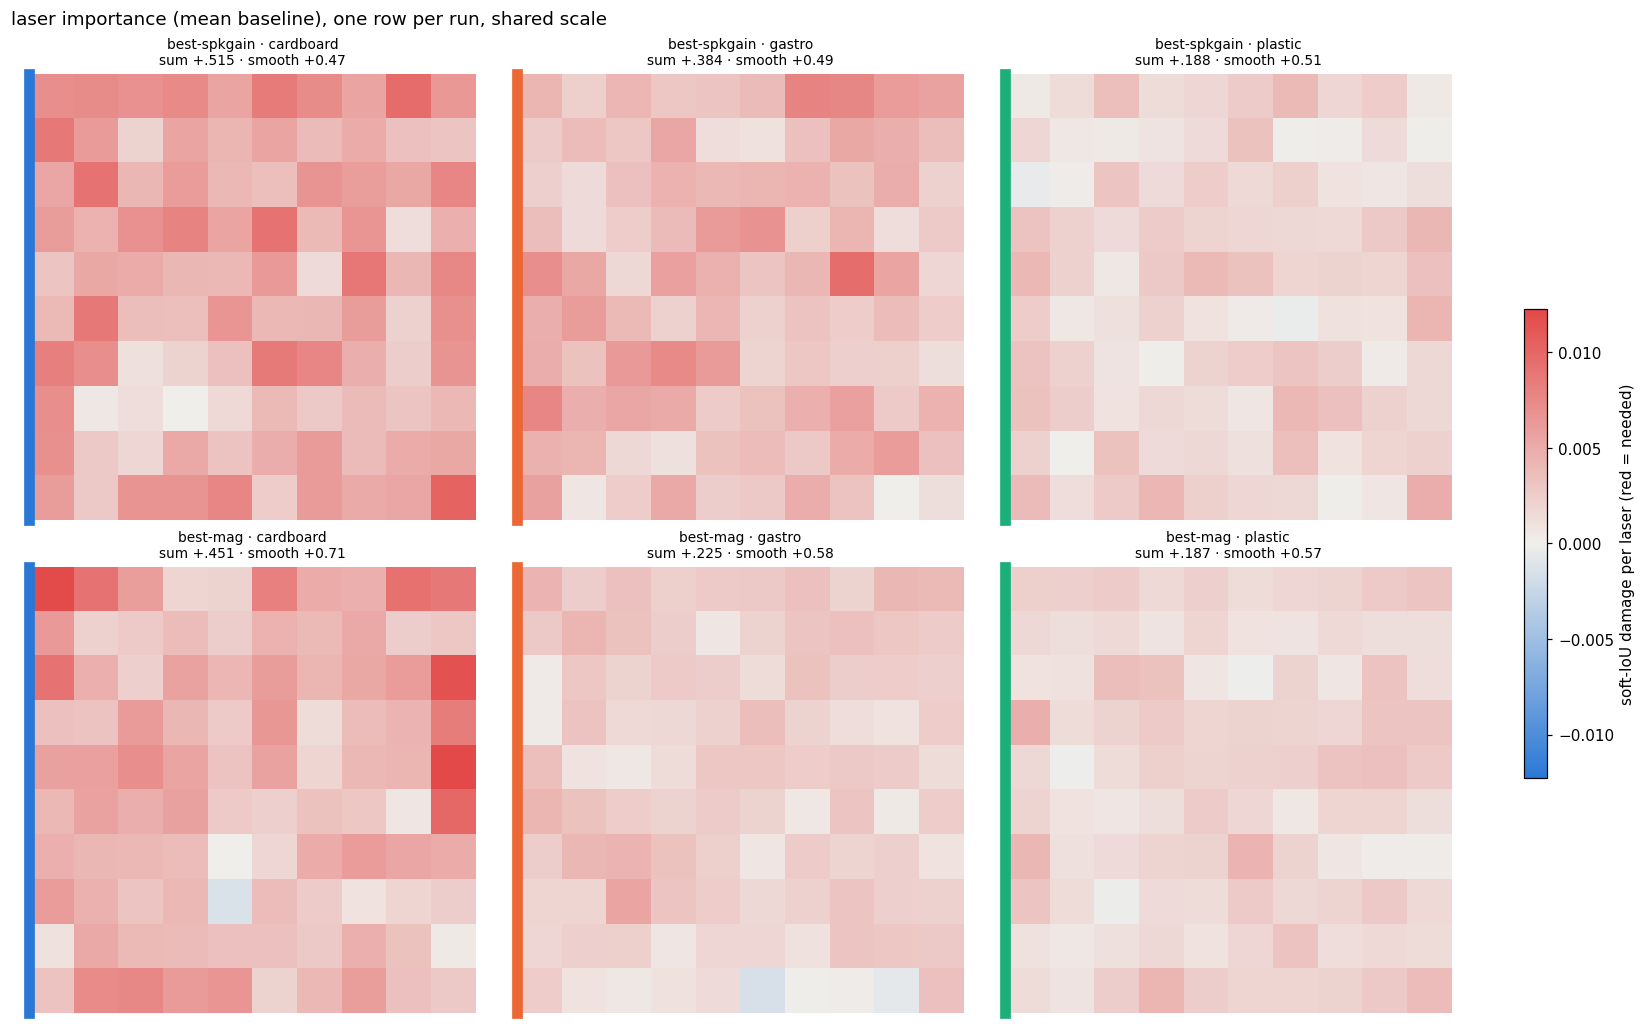

total                    top10                     edge  \
box          cardboard gastro plastic cardboard gastro plastic cardboard   
run                                                                        
best-spkgain     0.515  0.384   0.188     0.174  0.189   0.213     0.438   
best-mag         0.451  0.225   0.187     0.218  0.184   0.203     0.462   

                               smooth                 
box          gastro plastic cardboard gastro plastic  
run                                                   
best-spkgain  0.353   0.434     0.474  0.486   0.512  
best-mag      0.335   0.416     0.711  0.578   0.570

In [ ]:
ABL = ['s8-posesum-contour-500ep', 's8-best-jitter-500ep', 's8-best-spkgain-500ep', 's8-best-mag-500ep', 's8-mag-fjit-500ep', 's8-mag-drop-500ep']
A = {r: load(r)['mean'] for r in ABL if (ROOT / 'runs' / r / 'importance.pt').exists()}
A = {r: D for r, D in A.items() if 'soft_iou' in D['metrics']}
short = lambda r: r.replace('-500ep', '').replace('s8-', '')
def neighbour_corr(v):
    g = v.reshape(rows, cols); pad = np.pad(g, 1, mode='edge')
    nbr = (pad[:-2, 1:-1] + pad[2:, 1:-1] + pad[1:-1, :-2] + pad[1:-1, 2:]) / 4
    return np.corrcoef(g.ravel(), nbr.ravel())[0, 1]
edge = np.zeros((rows, cols), bool); edge[[0, -1]] = edge[:, [0, -1]] = True
if len(A) < 2: print('fewer than two of the ablation runs have importance yet:', list(A))
else:
    stats = []
    fig, axs = plt.subplots(len(A), nb, figsize=(15, 4.6 * len(A)), layout='constrained', squeeze=False)
    lim = max(np.nanmax(np.abs(D['laser'][D['metrics'].index('soft_iou')].numpy())) for D in A.values())
    for i, (r, D) in enumerate(A.items()):
        V = D['laser'][D['metrics'].index('soft_iou')].numpy()
        for b, bn in enumerate(boxes):
            v = V[b]; pos = np.clip(v, 0, None); srt = np.sort(pos)[::-1]
            stats.append(dict(run=short(r), box=bn, total=v.sum(), top10=srt[:10].sum() / pos.sum(), edge=pos[edge.ravel()].sum() / pos.sum(), smooth=neighbour_corr(v)))
            im = heat(axs[i, b], v.reshape(rows, cols), lim, annotate=False); tag(axs[i, b], b); axs[i, b].set_xticks([]); axs[i, b].set_yticks([])
            axs[i, b].set_title(f'{short(r)} · {bn}\nsum {fmt(v.sum())} · smooth {neighbour_corr(v):+.2f}', fontsize=9)
    fig.colorbar(im, ax=axs, shrink=.5, label='soft-IoU damage per laser (red = needed)'); fig.suptitle('laser importance (mean baseline), one row per run, shared scale', x=.01, ha='left'); plt.show()
    import pandas as pd
    S = pd.DataFrame(stats)
    display(S.pivot(index='run', columns='box', values=['total', 'top10', 'edge', 'smooth']).reindex([short(r) for r in A]).round(3))

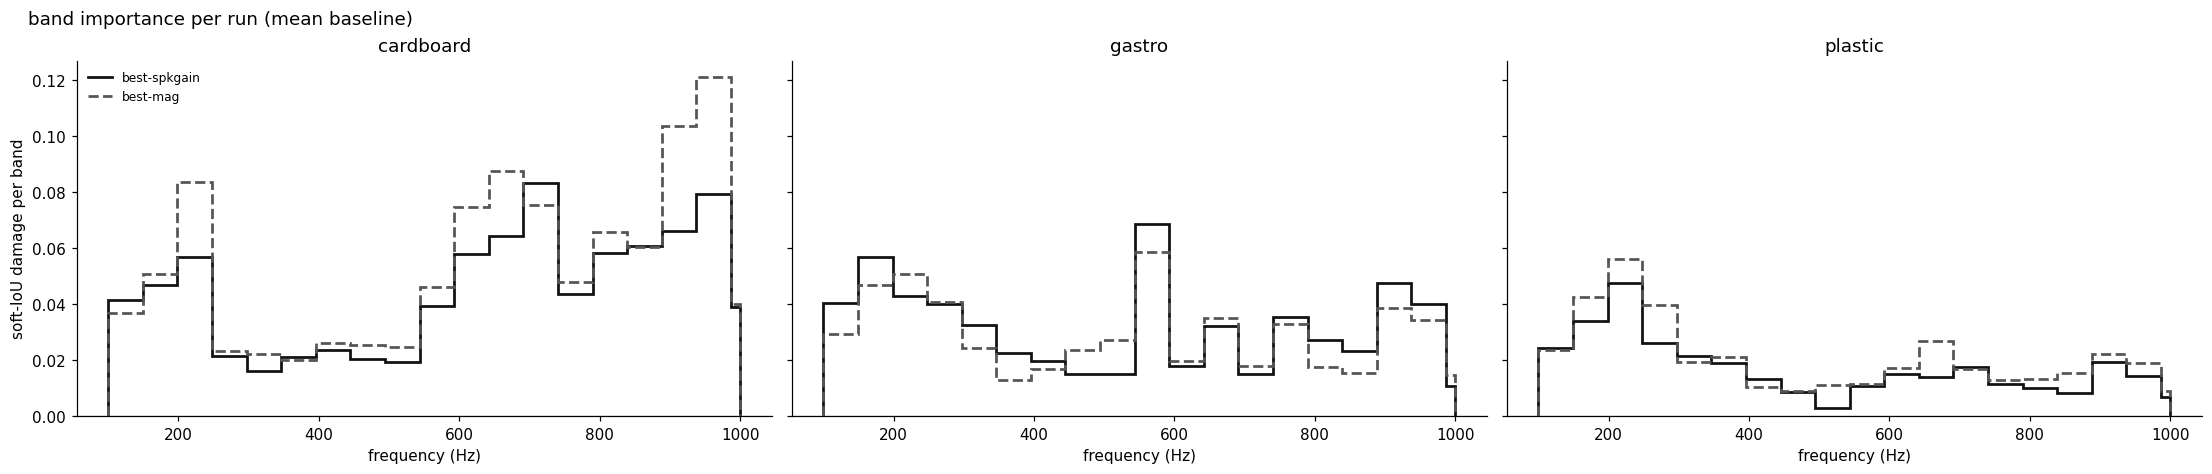

In [ ]:
if len(A) >= 2:
    fig, axs = plt.subplots(1, nb, figsize=(20, 4.2), sharey=True, layout='constrained')
    styles = ['-', '--', '-.', ':', '-', '--']; greys = ['#111', '#555', '#888', '#bbb', '#2a78d6', '#eb6834']
    for b, (ax, bn) in enumerate(zip(axs, boxes)):
        for (r, D), ls, c in zip(A.items(), styles, greys):
            b2 = [BOX_NAMES.get(x, x) for x in D['boxes']].index(bn)
            ax.stairs(D['band'][D['metrics'].index('soft_iou'), b2], EDGES, color=c, ls=ls, lw=1.8, label=short(r))
        ax.axhline(0, color='#888', lw=.8); ax.set_title(bn); ax.set_xlabel('frequency (Hz)')
    axs[0].set_ylabel('soft-IoU damage per band'); axs[0].legend(frameon=False, fontsize=8); fig.suptitle('band importance per run (mean baseline)', x=.01, ha='left'); plt.show()

In [ ]:
SP = ROOT / 'runs' / 'shift_probe.csv'
if not SP.exists(): print('shift_probe.csv not computed yet')
else:
    import pandas as pd
    sp = pd.read_csv(SP); runs_sp = [r for r in ABL if r in set(sp.run)]
    for kind, xl in (('laser', 'grid shift d (cells, along rows and columns)'), ('freq', 'frequency stretch ε (f → f(1+ε))')):
        fig, axs = plt.subplots(1, nb, figsize=(20, 4.2), sharey=True, layout='constrained')
        for b, (ax, bx) in enumerate(zip(axs, d['boxes'])):
            for r, ls, c in zip(runs_sp, ['-', '--', '-.', ':', '-', '--'], ['#111', '#555', '#888', '#bbb', '#2a78d6', '#eb6834']):
                q = sp[(sp.run == r) & (sp.kind == kind) & (sp.box == bx)].sort_values('amount')
                ax.plot(q.amount, q['iou@0.08'], ls, color=c, marker='o', ms=3, lw=1.8, label=short(r))
            ax.set_title(BOX_NAMES.get(bx, bx)); ax.set_xlabel(xl); ax.grid(axis='y', color='#eee')
            if kind == 'freq': ax.set_xscale('symlog', linthresh=2.5e-4)
        axs[0].set_ylabel('iou@0.08'); axs[0].legend(frameon=False, fontsize=8)
        fig.suptitle(f'tolerance to a fixed {kind} shift at eval', x=.01, ha='left'); plt.show()

shift_probe.csv not computed yet


## Takeaways
Numbers are soft-IoU drops on CORE + HARD, ep500 checkpoints. Base soft IoU for spkgain: cardboard .716, gastro .727, plastic .759.

**Frequency: a few bands matter, and which bands depends on the box.**
- **Cardboard reads high frequencies.** The top bands for spkgain are 715, 961, 912 and 666 Hz; only 26% of the importance is below 450 Hz. Cardboard is also the box most damaged by a single missing band: one band costs up to .08 soft IoU.
- **Plastic reads low frequencies.** The top bands are 223, 173, 272 and 124 Hz, and 57% of the importance is below 450 Hz. It is the least sensitive box overall: the band drops sum to .33, against .86 for cardboard.
- **Gastronorm mixes both:** 567, 173, 912 and 223 Hz.
- **Moderately concentrated:** the top 4 of 19 bands carry 34–42% of the importance, and half is reached with 6–7 bands. No single band dominates. This matches nb104, which found no dominant band.

**Lasers: diffuse, no hot spots.**
- The top 10 of 100 lasers carry only 17–22%, and half the importance needs about 30 lasers.
- The model does not favour the edge of the wall: the 36 edge lasers carry 34–46%, roughly their share.
- A single laser costs at most about .01. Each laser is redundant with its neighbours, which fits a model built on attention between lasers.

**The joint laser × band map is mostly noise.** A single (laser, band) cell carries too little signal to measure on 200 samples per box: the cell totals for plastic and gastronorm are about zero or even negative. Read the marginal band and laser plots, and the IG map, instead.

**Do the methods agree?** Spearman rank correlation between occlusion and IG:
- Bands: strong on cardboard (ρ .92 for spkgain, .73 for mag), moderate on gastronorm (.41 / .61), absent on plastic (≈0 / .23). Plastic's band drops are small, so its ranking is close to noise.
- Lasers: weak everywhere (ρ ≤ .46). The per-laser effects are too small to rank reliably.

**spkgain vs mag: the same story.** The same boxes rely on the same bands. Mag leans even harder on cardboard's high bands (961 Hz costs .12), and its gastro lasers are less individually important (total .23 vs .38).